# Deep-SSP required depth versus group connectivity \(G\)

This is the post-\(\gamma_{\max}\)-sweep experiment.

The architecture is now fixed to

\[
\gamma_{\max}^{(1)}=10,\qquad
\gamma_{\max}^{(2)}=3,\qquad
\beta_{\max}=0.95,\qquad N_s=10.
\]

For each \(G\in\{1,2,4,8\}\), the notebook trains a separate B3 model progressively in depth and uses **only the terminal normalized remaining gap** as the training and validation criterion:

\[
\mathcal L_N=\frac{1}{B}\sum_q
\frac{[f_{\rm ref,q}-f_q^{(N)}]_+}
{f_{\rm ref,q}-f_q^{(0)}+\epsilon}.
\]

There is no weighted AUC/final loss. The model is extended as

\[
60\rightarrow100\rightarrow150\rightarrow200\rightarrow250\rightarrow300\rightarrow350\rightarrow400\rightarrow500
\]

until the validation terminal gap is below 1%. All completed stages are checkpointed.

Two depth notions are reported:

1. **trained-depth requirement**: the smallest trained candidate depth whose terminal gap crosses 5% or 1%;
2. **early-exit requirement**: the first executed layer of the selected long model whose gap crosses 5% or 1%.

The selected long model's first 40 layers are also exported as the natural \(N_{\rm exe}=40\) low-latency baseline for later figures.


## 1. Exact SSP / Deep-SSP model definitions


In [1]:
import copy
import time
import math
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

class DeepHBFSGPI(nn.Module):
    """
    Deep-unfolded SGPI for ISAC hybrid beamforming.

    Difference from the digital/reduced-domain Deep-SGPI:
        - The low-dimensional representation W = U X is NOT used.
        - The full-dimensional SGPI target W_tmp is first constructed.
        - W_tmp is then approximated by a hybrid beamformer W = Wa Wd,
          where Wa is the analog beamformer with unit-modulus entries and
          Wd is the digital baseband beamformer.
        - The learnable parameters are the iteration-specific shift values mu[n].

    This follows the MATLAB HBF_SGPI algorithm:
        grad_c = delta_c / SR_ref  * (H Sigma1 - H Sigma2 H^H W)
        grad_s = delta_s / CRB_ref * Q(W)
        W_tmp  = grad_c + grad_s + mu[n] W
        [Wa,Wd] = matrix_approximation(W_tmp, Wa, Wd)
        Wd = sqrt(Pt) * Wd / ||Wa Wd||_F
        W  = Wa Wd
    """

    def __init__(
        self,
        num_iter: int,
        device="cpu",
        init_mu=10.0,
        mu_min=1e-5,
        mu_max=100.0,
        nrf=None,
        hbf_outer_iter=20,
        hbf_inner_iter=5,
    ):
        super().__init__()
        self.num_iter = num_iter
        self.device = device
        self.nrf = nrf
        self.hbf_outer_iter = hbf_outer_iter
        self.hbf_inner_iter = hbf_inner_iter
        
        self.mu_min = mu_min
        self.mu_max = mu_max

        tau_min = 1.0 / self.mu_max
        tau_max = 1.0 / self.mu_min
        self.tau_min = tau_min
        self.tau_max = tau_max

        init_tau = 1.0 / init_mu
        init_ratio = (init_tau - tau_min) / (tau_max - tau_min)
        init_ratio = min(max(init_ratio, 1e-6), 1.0 - 1e-6)

        self.tau_raw = nn.Parameter(
            torch.logit(torch.tensor(init_ratio, device=device, dtype=torch.float32))
            * torch.ones(num_iter, device=device)
        )

    def get_mu(self):
        tau = self.tau_min + (self.tau_max - self.tau_min) * torch.sigmoid(self.tau_raw)
        return 1.0 / tau

    def forward(
        self,
        h,
        noise_c,
        pt,
        lents,
        noise_s,
        delta_s,
        delta_c,
        alpha,
        theta,
        phi,
        upa_set,
        num_iter=None,
        return_all=False,
    ):
        if num_iter is None:
            num_iter = self.num_iter
        num_iter = min(num_iter, self.num_iter)

        device = h.device
        dtype = torch.complex64
        h = h.to(device=device, dtype=dtype)

        batch_size, nt, k = h.shape
        nrf = k if self.nrf is None else int(self.nrf)
        nth, ntv, nrh, nrv = [int(x) for x in upa_set]

        # Construct transmit/receive steering matrices.
        A, dAtheta, dAphi = self.construct_steer_matrix_and_derivative_steer_matrix(
            theta, phi, nth, ntv, device
        )
        B, dBtheta, dBphi = self.construct_steer_matrix_and_derivative_steer_matrix(
            theta, phi, nrh, nrv, device
        )

        # Full-dimensional sensing precomputations. No reduced basis U is used.
        pre = self.precompute_full_matrices(
            A, dAtheta, dAphi, B, dBtheta, dBphi, alpha, lents, noise_s
        )

        # HBF initialization: Wa = exp(j angle(H)), Wd = I, as in the MATLAB code.
        Wa = self.initialize_analog_from_channel(h, nrf)
        Wd = torch.zeros(batch_size, nrf, k, dtype=dtype, device=device)
        diag_len = min(nrf, k)
        Wd[:, torch.arange(diag_len, device=device), torch.arange(diag_len, device=device)] = 1.0 + 0.0j
        Wd = self.normalize_digital_power(Wa, Wd, pt)
        W = torch.bmm(Wa, Wd)

        obj_total = torch.zeros(batch_size, num_iter, device=device)
        obj_comm = torch.zeros(batch_size, num_iter, device=device)
        obj_sens = torch.zeros(batch_size, num_iter, device=device)

        mu_all = self.get_mu()

        for ell in range(num_iter):
            # Communication auxiliary variables.
            HW = torch.bmm(h.conj().transpose(1, 2), W)  # [B,K,K]
            abs_HW2 = self.square_abs(HW)
            T_k = torch.sum(abs_HW2, dim=-1) + self._real_scalar(noise_c, device)
            desired = torch.diagonal(abs_HW2, dim1=-2, dim2=-1)
            interf_noise = T_k - desired
            alpha_k = T_k / (interf_noise + 1e-12) - 1.0
            diag_HW = torch.diagonal(HW, dim1=-2, dim2=-1)
            beta_k = torch.sqrt(torch.clamp(1.0 + alpha_k.real, min=1e-12)) * diag_HW / (T_k + 1e-12)

            Sigma1 = torch.diag_embed(torch.sqrt(torch.clamp(1.0 + alpha_k.real, min=1e-12)) * beta_k)
            Sigma2 = torch.diag_embed(self.square_abs(beta_k).to(dtype))

            # FIM inverse and sensing gradient.
            FIM = self.calculate_FIM_full_batch(pre, W)
            CRB = self.safe_inverse(FIM)
            Phi = torch.bmm(CRB, CRB).to(dtype)


            grad_c = torch.bmm(h, Sigma1) - torch.bmm(
                torch.bmm(h, Sigma2), torch.bmm(h.conj().transpose(1, 2), W)
            )
            grad_s = self.compute_QW_full_batch(pre, Phi, W)

         
          
            grad_c = self._real_scalar(delta_c, device) * grad_c
            grad_s = self._real_scalar(delta_s, device) * grad_s

            grad_total = grad_c + grad_s

            # Deep-unfolded HBF-SGPI update.
            mu_l = mu_all[ell].to(dtype)
            W_tmp = grad_total + mu_l * W

            # Hybrid matrix approximation and power normalization.
            Wa, Wd = self.matrix_approximation_batch(W_tmp, Wa, Wd)
            Wd = self.normalize_digital_power(Wa, Wd, pt)
            W = torch.bmm(Wa, Wd)

            FIM_new = self.calculate_FIM_full_batch(pre, W)
            CRB_new = self.safe_inverse(FIM_new)
            obj_total[:, ell], obj_comm[:, ell], obj_sens[:, ell] = self.calculate_obj_full(
                h, W, noise_c, CRB_new, delta_s, delta_c
            )
        # log(n) weights:
        # obj_layer = torch.mean(obj_total, dim=0)
        # layer_idx = torch.arange(1, self.num_iter + 1, device=device, dtype=torch.float32)
        # early_w = 1.0 / layer_idx # 1/n
        # layer_w = torch.log(layer_idx);
        # layer_w = layer_w / layer_w.sum()

        # loss = 0.0
        # for ell in range(self.num_iter):
        #     loss = loss - layer_w[ell] * obj_layer[ell].mean()

        # 1/n weights
        obj_layer = torch.mean(obj_total, dim=0)

        layer_idx = torch.arange(
            1,
            self.num_iter + 1,
            device=device,
            dtype=obj_layer.dtype
        )
        
        layer_w = 1.0 / layer_idx
        layer_w = layer_w / layer_w.sum()
        
        loss = -torch.sum(layer_w * obj_layer)

        #hybrid weight
        # obj_layer = torch.mean(obj_total, dim=0)

        # lambda_inter = 0.9
        
        # layer_idx = torch.arange(
        #     1,
        #     self.num_iter,
        #     device=device,
        #     dtype=obj_layer.dtype,
        # )
        
        # inter_w = 1.0 / layer_idx
        # inter_w = inter_w / inter_w.sum()
        
        # final_loss = -obj_layer[-1]
        # inter_loss = -torch.sum(inter_w * obj_layer[:-1])
        
        # loss = final_loss + lambda_inter * inter_loss
        # # ============================================================
        # # Final performance + fast convergence + monotonicity
        # # ============================================================
        
        # obj_layer = torch.mean(obj_total, dim=0)
        
        # # ------------------------------------------------------------
        # # 1) Final-layer objective
        # # ------------------------------------------------------------
        # final_loss = -obj_layer[-1]
        
        
        # # ------------------------------------------------------------
        # # 2) Early-layer supervision
        # # ------------------------------------------------------------
        # lambda_inter = 0.5
        
        # layer_idx = torch.arange(
        #     1,
        #     self.num_iter,
        #     device=device,
        #     dtype=obj_layer.dtype,
        # )
        
        # inter_w = 1.0 / layer_idx
        # inter_w = inter_w / inter_w.sum()
        
        # inter_loss = -torch.sum(
        #     inter_w * obj_layer[:-1]
        # )
        
        
        # # ------------------------------------------------------------
        # # 3) Penalize objective decreases between consecutive layers
        # # ------------------------------------------------------------
        # lambda_mono = 100.0
        
        # obj_improvement = (
        #     obj_total[:, 1:] - obj_total[:, :-1]
        # )
        
        # # Positive only when the objective decreases
        # mono_loss = torch.relu(
        #     -obj_improvement
        # ).mean()
        
        
        # # ------------------------------------------------------------
        # # Total loss
        # # ------------------------------------------------------------
        # loss = (
        #     final_loss
        #     + lambda_inter * inter_loss
        #     + lambda_mono * mono_loss
        # )

        

        if return_all:
            return obj_total, obj_comm, obj_sens, W, loss, Wa, Wd
        return obj_total, obj_comm, obj_sens, W, loss

    @staticmethod
    def initialize_analog_from_channel(h, nrf):
        """Initialize Wa from channel phases. If nrf > K, remaining RF chains are random."""
        batch_size, nt, k = h.shape
        device = h.device
        dtype = torch.complex64
        if nrf <= k:
            Wa0 = h[:, :, :nrf]
        else:
            rand_extra = torch.randn(batch_size, nt, nrf - k, device=device) + 1j * torch.randn(batch_size, nt, nrf - k, device=device)
            Wa0 = torch.cat([h, rand_extra.to(dtype)], dim=-1)
        return torch.exp(1j * torch.angle(Wa0)).to(dtype)

    @staticmethod
    def matrix_approximation_batch(W_target, Wa, Wd, outer_iter=20, inner_iter=5):
        """
        Batch version of the MATLAB matrix_approximation function.

        W_target: [B,Nt,K]
        Wa:       [B,Nt,Nrf], unit modulus
        Wd:       [B,Nrf,K]
        """
        # Use the class defaults if called through an instance wrapper.
        for _ in range(outer_iter):
            # Digital update: least-squares solution min_Wd ||W_target - Wa Wd||_F^2.
            Wd = torch.linalg.lstsq(Wa, W_target).solution

            Rwd = torch.bmm(Wd, Wd.conj().transpose(1, 2))  # [B,Nrf,Nrf]
            mu1 = DeepHBFSGPI.gershgorin_shift_batch(Rwd).view(-1, 1, 1).to(W_target.dtype)

            for _ in range(inner_iter):
                Wa = -torch.bmm(Wa, Rwd) + torch.bmm(W_target, Wd.conj().transpose(1, 2)) + mu1 * Wa
                Wa = torch.exp(1j * torch.angle(Wa)).to(W_target.dtype)

        return Wa, Wd

    def matrix_approximation_batch(self, W_target, Wa, Wd):
        for _ in range(self.hbf_outer_iter):
            Wd = torch.linalg.lstsq(Wa, W_target).solution

            Rwd = torch.bmm(Wd, Wd.conj().transpose(1, 2))
            mu1 = self.gershgorin_shift_batch(Rwd).view(-1, 1, 1).to(W_target.dtype)

            for _ in range(self.hbf_inner_iter):
                Wa = -torch.bmm(Wa, Rwd) + torch.bmm(W_target, Wd.conj().transpose(1, 2)) + mu1 * Wa
                Wa = torch.exp(1j * torch.angle(Wa)).to(W_target.dtype)

        return Wa, Wd

    @staticmethod
    def gershgorin_shift_batch(C):
        diag_abs = torch.abs(torch.diagonal(C, dim1=-2, dim2=-1))
        row_sum = torch.sum(torch.abs(C), dim=-1) - diag_abs
        diag_real = torch.diagonal(C, dim1=-2, dim2=-1).real
        return torch.max(diag_real + row_sum, dim=-1).values + 1e-6

    @staticmethod
    def normalize_digital_power(Wa, Wd, pt):
        W = torch.bmm(Wa, Wd)
        pt_real = DeepHBFSGPI._real_scalar(pt, W.device)
        normW = torch.linalg.norm(W, dim=(1, 2), keepdim=True)
        return torch.sqrt(pt_real) * Wd / (normW + 1e-12)

    @staticmethod
    def precompute_full_matrices(A, dAtheta, dAphi, B, dBtheta, dBphi, gamma, L, noise_s):
        dtype = torch.complex64
        gamma = gamma.to(dtype)
        Gamma = torch.diag_embed(gamma)

        AH = A.conj().transpose(1, 2)
        dAthH = dAtheta.conj().transpose(1, 2)
        dAphH = dAphi.conj().transpose(1, 2)

        return {
            "L": L,
            "noise_s": noise_s,
            "tilde_A": AH,
            "tilde_A_o": torch.bmm(Gamma, AH),
            "tilde_A_th": torch.bmm(Gamma, dAthH),
            "tilde_A_ph": torch.bmm(Gamma, dAphH),
            "tilde_B_oo": torch.bmm(B.conj().transpose(1, 2), B),
            "tilde_B_oth": torch.bmm(B.conj().transpose(1, 2), dBtheta),
            "tilde_B_oph": torch.bmm(B.conj().transpose(1, 2), dBphi),
            "tilde_B_tho": torch.bmm(dBtheta.conj().transpose(1, 2), B),
            "tilde_B_thth": torch.bmm(dBtheta.conj().transpose(1, 2), dBtheta),
            "tilde_B_thph": torch.bmm(dBtheta.conj().transpose(1, 2), dBphi),
            "tilde_B_pho": torch.bmm(dBphi.conj().transpose(1, 2), B),
            "tilde_B_phph": torch.bmm(dBphi.conj().transpose(1, 2), dBphi),
        }

    @staticmethod
    def calculate_FIM_full_batch(pre, W, eps_fim=1e-6):
        """
        Efficient FIM computation without explicitly forming Rw = W W^H.
    
        Original:
            X Rw Y^H = X W W^H Y^H
    
        Efficient:
            X Rw Y^H = (X W) (Y W)^H
    
        Complexity is reduced from O(Nt^2) to O(M K Nt), assuming X,Y are M x Nt
        and W is Nt x K.
        """
    
        device = W.device
    
        A   = pre["tilde_A"]
        Ao  = pre["tilde_A_o"]
        Ath = pre["tilde_A_th"]
        Aph = pre["tilde_A_ph"]
    
        Boo    = pre["tilde_B_oo"]
        Both   = pre["tilde_B_oth"]
        Boph   = pre["tilde_B_oph"]
        Btho   = pre["tilde_B_tho"]
        Bthth  = pre["tilde_B_thth"]
        Bthph  = pre["tilde_B_thph"]
        Bpho   = pre["tilde_B_pho"]
        Bphph  = pre["tilde_B_phph"]
    
        # ======================================================
        # 1) Compute low-dimensional projections XW
        # ======================================================
        AW   = torch.bmm(A,   W)   # batch x M x K
        AoW  = torch.bmm(Ao,  W)   # batch x M x K
        AthW = torch.bmm(Ath, W)   # batch x M x K
        AphW = torch.bmm(Aph, W)   # batch x M x K
    
        # ======================================================
        # 2) Efficiently compute X W W^H Y^H
        #    The final transpose is kept to match your original X_R_YH()
        # ======================================================
        def XW_YWH(XW, YW):
            return torch.bmm(
                XW,
                YW.conj().transpose(1, 2)
            ).transpose(1, 2)
    
        Ao_Ao   = XW_YWH(AoW,  AoW)
        Ao_Ath  = XW_YWH(AoW,  AthW)
        Ath_Ao  = XW_YWH(AthW, AoW)
        Ath_Ath = XW_YWH(AthW, AthW)
    
        Ao_Aph  = XW_YWH(AoW,  AphW)
        Aph_Ao  = XW_YWH(AphW, AoW)
        Aph_Ath = XW_YWH(AphW, AthW)
        Aph_Aph = XW_YWH(AphW, AphW)
    
        A_Ao    = XW_YWH(AW,   AoW)
        A_Ath   = XW_YWH(AW,   AthW)
        A_Aph   = XW_YWH(AW,   AphW)
        A_A     = XW_YWH(AW,   AW)
    
        # ======================================================
        # 3) Construct FIM blocks
        # ======================================================
        F11 = (
            Ao_Ao   * Bthth
            + Ao_Ath  * Both
            + Ath_Ao  * Btho
            + Ath_Ath * Boo
        )
    
        F12 = (
            Ao_Ao   * Bthph
            + Ao_Ath  * Boph
            + Aph_Ao  * Btho
            + Aph_Ath * Boo
        )
    
        F13 = (
            A_Ao  * Btho
            + A_Ath * Boo
        )
    
        F22 = (
            Ao_Ao   * Bphph
            + Ao_Aph  * Boph
            + Aph_Ao  * Bpho
            + Aph_Aph * Boo
        )
    
        F23 = (
            A_Ao  * Bpho
            + A_Aph * Boo
        )
    
        F33 = A_A * Boo
    
        # ======================================================
        # 4) Assemble real FIM
        # ======================================================
        batch_size, M, _ = Boo.shape
    
        FIM = torch.zeros(
            batch_size,
            4 * M,
            4 * M,
            dtype=torch.float32,
            device=device
        )
    
        FIM[:, 0:M,       0:M      ] = F11.real
        FIM[:, 0:M,       M:2*M    ] = F12.real
        FIM[:, 0:M,       2*M:3*M  ] = F13.real
        FIM[:, 0:M,       3*M:4*M  ] = -F13.imag
    
        FIM[:, M:2*M,     M:2*M    ] = F22.real
        FIM[:, M:2*M,     2*M:3*M  ] = F23.real
        FIM[:, M:2*M,     3*M:4*M  ] = -F23.imag
    
        FIM[:, 2*M:3*M,   2*M:3*M  ] = F33.real
        FIM[:, 2*M:3*M,   3*M:4*M  ] = -F33.imag
    
        FIM[:, 3*M:4*M,   3*M:4*M  ] = F33.real
    
        # Symmetrize
        FIM = torch.triu(FIM) + torch.triu(FIM, diagonal=1).transpose(1, 2)
    
        # Scaling
        FIM = (
            2.0
            * DeepHBFSGPI._real_scalar(pre["L"], device)
            / DeepHBFSGPI._real_scalar(pre["noise_s"], device)
            * FIM
        )
    
        # Optional diagonal loading for training stability
        if eps_fim is not None and eps_fim > 0:
            jitter = eps_fim * torch.eye(4 * M, device=device).unsqueeze(0)
            FIM = FIM + jitter
    
        return FIM

    @staticmethod
    def compute_QW_full_batch(pre, Phi, W):
        """
        Efficient batch implementation of the sensing-gradient term Q(W),
        matching compute_QW in the MATLAB HBF_SGPI code.
        """
        device = W.device
        dtype = torch.complex64
        M = pre["tilde_B_oo"].shape[1]

        phi11 = Phi[:, 0:M, 0:M]
        phi12 = Phi[:, 0:M, M:2*M]
        phi13 = Phi[:, 0:M, 2*M:3*M]
        phi14 = Phi[:, 0:M, 3*M:4*M]
        phi22 = Phi[:, M:2*M, M:2*M]
        phi23 = Phi[:, M:2*M, 2*M:3*M]
        phi24 = Phi[:, M:2*M, 3*M:4*M]
        phi33 = Phi[:, 2*M:3*M, 2*M:3*M]
        phi34 = Phi[:, 2*M:3*M, 3*M:4*M]
        phi44 = Phi[:, 3*M:4*M, 3*M:4*M]

        At = pre["tilde_A"]
        Ato = pre["tilde_A_o"]
        Atth = pre["tilde_A_th"]
        Atph = pre["tilde_A_ph"]
        Boo = pre["tilde_B_oo"]
        Both = pre["tilde_B_oth"]
        Boph = pre["tilde_B_oph"]
        Btho = pre["tilde_B_tho"]
        Bthth = pre["tilde_B_thth"]
        Bthph = pre["tilde_B_thph"]
        Bpho = pre["tilde_B_pho"]
        Bphph = pre["tilde_B_phph"]

        Moo = phi11 * Bthth + 2 * phi12 * Bthph + phi22 * Bphph
        Mtho = 2 * (phi11 * Both + phi12 * Boph)
        Mpho = 2 * (phi22 * Boph)
        Moph = 2 * (phi12 * Btho)
        Mthph = 2 * (phi12 * Boo)
        Mthth = phi11 * Boo
        Mphph = phi22 * Boo
        Mo3 = (2 * phi13 + 2j * phi14) * Btho + (2 * phi23 + 2j * phi24) * Bpho
        Mth3 = (2 * phi13 + 2j * phi14) * Boo
        Mph3 = (2 * phi23 + 2j * phi24) * Boo
        M33 = (phi33 + phi44 + 2j * phi34) * Boo

        # M x K projected beamformers.
        Wo = torch.bmm(Ato, W)
        Wth = torch.bmm(Atth, W)
        Wph = torch.bmm(Atph, W)
        Wa = torch.bmm(At, W)

        def H(X):
            return X.conj().transpose(1, 2)

        QrawW = (
            torch.bmm(H(Ato), torch.bmm(Moo, Wo))
            + torch.bmm(H(Atth), torch.bmm(Mtho, Wo))
            + torch.bmm(H(Atph), torch.bmm(Mpho, Wo))
            + torch.bmm(H(Ato), torch.bmm(Moph, Wph))
            + torch.bmm(H(Atth), torch.bmm(Mthph, Wph))
            + torch.bmm(H(Atph), torch.bmm(Mphph, Wph))
            + torch.bmm(H(Atth), torch.bmm(Mthth, Wth))
            + torch.bmm(H(Ato), torch.bmm(Mo3, Wa))
            + torch.bmm(H(Atth), torch.bmm(Mth3, Wa))
            + torch.bmm(H(Atph), torch.bmm(Mph3, Wa))
            + torch.bmm(H(At), torch.bmm(M33, Wa))
        )

        QrawHW = (
            torch.bmm(H(Ato), torch.bmm(H(Moo), Wo))
            + torch.bmm(H(Ato), torch.bmm(H(Mtho), Wth))
            + torch.bmm(H(Ato), torch.bmm(H(Mpho), Wph))
            + torch.bmm(H(Atph), torch.bmm(H(Moph), Wo))
            + torch.bmm(H(Atph), torch.bmm(H(Mthph), Wth))
            + torch.bmm(H(Atph), torch.bmm(H(Mphph), Wph))
            + torch.bmm(H(Atth), torch.bmm(H(Mthth), Wth))
            + torch.bmm(H(At), torch.bmm(H(Mo3), Wo))
            + torch.bmm(H(At), torch.bmm(H(Mth3), Wth))
            + torch.bmm(H(At), torch.bmm(H(Mph3), Wph))
            + torch.bmm(H(At), torch.bmm(H(M33), Wa))
        )

        QW = DeepHBFSGPI._real_scalar(pre["L"], device) / DeepHBFSGPI._real_scalar(pre["noise_s"], device) * (QrawW + QrawHW)
        return QW.to(dtype)

    @staticmethod
    def calculate_obj_full(H, W, noise_c, CRB, delta_s, delta_c):
        device = W.device
        HW = torch.bmm(H.conj().transpose(1, 2), W)
        abs_HW2 = DeepHBFSGPI.square_abs(HW)
        T_k = torch.sum(abs_HW2, dim=-1) + DeepHBFSGPI._real_scalar(noise_c, device)
        desired = torch.diagonal(abs_HW2, dim1=-2, dim2=-1)
        rate_k = torch.log(T_k / (T_k - desired + 1e-12))
        sr = torch.sum(rate_k, dim=-1)
        tr_crb = torch.diagonal(CRB, dim1=-2, dim2=-1).sum(-1)
        total = DeepHBFSGPI._real_scalar(delta_c, device) * sr - DeepHBFSGPI._real_scalar(delta_s, device) * tr_crb
        return total.real, sr.real, tr_crb.real

    @staticmethod
    def safe_inverse(FIM):
        FIM = 0.5 * (FIM + FIM.transpose(1, 2))
        batch_size, n, _ = FIM.shape
        device = FIM.device
        eye = torch.eye(n, device=device).unsqueeze(0)
        try:
            L = torch.linalg.cholesky(FIM + 1e-6 * eye)
            return torch.cholesky_inverse(L)
        except RuntimeError:
            return torch.linalg.pinv(FIM + 1e-6 * eye)

    @staticmethod
    def square_abs(x):
        return x.real ** 2 + x.imag ** 2

    @staticmethod
    def _real_scalar(x, device):
        if torch.is_tensor(x):
            return x.to(device=device).real.float()
        return torch.tensor(float(x), device=device)

    @staticmethod
    def construct_steer_matrix_and_derivative_steer_matrix(theta, phi, Mx, My, device):
        theta = theta.to(device)
        phi = phi.to(device)
        batch_size, M = theta.shape
        dtype = torch.complex64

        ix = torch.arange(0, Mx, device=device).view(-1, 1)
        iy = torch.arange(0, My, device=device).view(-1, 1)

        A = torch.zeros((batch_size, Mx * My, M), dtype=dtype, device=device)
        dAtheta = torch.zeros_like(A)
        dAphi = torch.zeros_like(A)

        sqrt_mx = torch.sqrt(torch.tensor(Mx, device=device, dtype=torch.float32))
        sqrt_my = torch.sqrt(torch.tensor(My, device=device, dtype=torch.float32))

        for b in range(batch_size):
            for m in range(M):
                ax = (1.0 / sqrt_mx) * torch.exp(
                    1j * torch.pi * ix * torch.sin(theta[b, m]) * torch.sin(phi[b, m])
                )
                ay = (1.0 / sqrt_my) * torch.exp(
                    1j * torch.pi * iy * torch.cos(phi[b, m])
                )
                daxtheta = 1j * torch.pi * ix * torch.cos(theta[b, m]) * torch.sin(phi[b, m]) * ax
                daxphi = 1j * torch.pi * ix * torch.sin(theta[b, m]) * torch.cos(phi[b, m]) * ax
                dayphi = -1j * torch.pi * iy * torch.sin(phi[b, m]) * ay

                A[b, :, m] = torch.kron(ay[:, 0], ax[:, 0])
                dAtheta[b, :, m] = torch.kron(ay[:, 0], daxtheta[:, 0])
                dAphi[b, :, m] = torch.kron(ay[:, 0], daxphi[:, 0]) + torch.kron(dayphi[:, 0], ax[:, 0])

        return A, dAtheta, dAphi

def balanced_group_connected_mask(nt, nrf, num_groups, device="cpu"):
    """Balanced block-connected analog mask.

    G = 1   -> fully connected
    G = Nrf -> sub-connected
    """
    num_groups = int(num_groups)
    if not 1 <= num_groups <= min(nt, nrf):
        raise ValueError("Require 1 <= num_groups <= min(Nt, Nrf).")

    antenna_groups = torch.tensor_split(
        torch.arange(nt, device=device), num_groups
    )
    rf_groups = torch.tensor_split(
        torch.arange(nrf, device=device), num_groups
    )

    if any(g.numel() == 0 for g in antenna_groups + rf_groups):
        raise ValueError("Every group must contain antennas and RF chains.")

    mask = torch.zeros(nt, nrf, dtype=torch.float32, device=device)
    for antenna_idx, rf_idx in zip(antenna_groups, rf_groups):
        mask[antenna_idx[:, None], rf_idx[None, :]] = 1.0

    return mask


class GroupConnectedDeepHBFSGPI(DeepHBFSGPI):
    """Deep-unfolded SGPI with a group-connected analog beamformer."""

    def __init__(
        self,
        num_iter,
        nt,
        num_groups,
        device="cpu",
        init_mu=10.0,
        mu_min=1e-3,
        mu_max=100.0,
        nrf=None,
        hbf_outer_iter=5,
        hbf_inner_iter=2,
    ):
        if nrf is None:
            raise ValueError("nrf is required for group-connected HBF.")

        super().__init__(
            num_iter=num_iter,
            device=device,
            init_mu=init_mu,
            mu_min=mu_min,
            mu_max=mu_max,
            nrf=nrf,
            hbf_outer_iter=hbf_outer_iter,
            hbf_inner_iter=hbf_inner_iter,
        )

        self.nt = int(nt)
        self.num_groups = int(num_groups)
        self.register_buffer(
            "group_mask",
            balanced_group_connected_mask(
                self.nt, int(nrf), self.num_groups, device=device
            ),
        )
        self.last_projection_residuals = None

    @property
    def connectivity_ratio(self):
        return float(self.group_mask.mean().detach().cpu())

    def initialize_analog_from_channel(self, h, nrf):
        batch_size, nt, k = h.shape
        if nt != self.nt:
            raise ValueError(f"Expected Nt={self.nt}, received Nt={nt}.")

        dtype = torch.complex64
        if nrf <= k:
            Wa0 = h[:, :, :nrf]
        else:
            random_extra = (
                torch.randn(batch_size, nt, nrf - k, device=h.device)
                + 1j * torch.randn(batch_size, nt, nrf - k, device=h.device)
            )
            Wa0 = torch.cat([h, random_extra.to(dtype)], dim=-1)

        mask = self.group_mask.to(device=h.device, dtype=dtype).unsqueeze(0)
        return torch.exp(1j * torch.angle(Wa0)).to(dtype) * mask

    def matrix_approximation_batch(self, W_target, Wa, Wd):
        dtype = W_target.dtype
        mask = self.group_mask.to(
            device=W_target.device, dtype=dtype
        ).unsqueeze(0)

        for _ in range(self.hbf_outer_iter):
            Wd = torch.linalg.lstsq(Wa, W_target).solution
            Rwd = torch.bmm(Wd, Wd.conj().transpose(1, 2))
            mu1 = self.gershgorin_shift_batch(Rwd).view(
                -1, 1, 1
            ).to(dtype)

            for _ in range(self.hbf_inner_iter):
                analog_update = (
                    -torch.bmm(Wa, Rwd)
                    + torch.bmm(
                        W_target, Wd.conj().transpose(1, 2)
                    )
                    + mu1 * Wa
                )
                Wa = (
                    torch.exp(1j * torch.angle(analog_update)).to(dtype)
                    * mask
                )

        approximation = torch.bmm(Wa, Wd)
        numerator = (
            W_target - approximation
        ).abs().square().sum(dim=(-2, -1))
        denominator = (
            W_target.abs().square().sum(dim=(-2, -1)).clamp_min(1e-12)
        )
        self._projection_residual_history.append(
            (numerator / denominator).detach()
        )

        return Wa, Wd

    def forward(self, *args, **kwargs):
        self._projection_residual_history = []
        output = super().forward(*args, **kwargs)
        self.last_projection_residuals = torch.stack(
            self._projection_residual_history, dim=1
        )
        return output

    @torch.no_grad()
    def set_mu_schedule(self, mu):
        mu = torch.as_tensor(
            mu, device=self.tau_raw.device, dtype=self.tau_raw.dtype
        )
        if mu.numel() != self.num_iter:
            raise ValueError(
                f"Expected {self.num_iter} shifts, received {mu.numel()}."
            )

        mu = mu.clamp(self.mu_min, self.mu_max)
        tau = 1.0 / mu
        ratio = (
            (tau - self.tau_min)
            / (self.tau_max - self.tau_min)
        ).clamp(1e-6, 1.0 - 1e-6)
        self.tau_raw.copy_(torch.logit(ratio))

# ============================================================
# model-based SSP-HBF with local-curvature shifts
# ============================================================

class LocalCurvatureGCSSP(GroupConnectedDeepHBFSGPI):
    """
    Conventional GC SSP-HBF with the local-curvature shift

        rho[t] = |eta_dom(R Omega2[t] R^H)|

    and objective-based backtracking safeguard.

    This is intended to generate the converged SSP reference / supervisor.
    It keeps:
        - exactly the same GC mask,
        - exactly the same HBF initialization,
        - exactly the same matrix_approximation_batch(),
        - exactly the same HBF outer/inner budgets.
    """

    def __init__(
        self,
        *args,
        max_backtrack=20,
        backtrack_factor=2.0,
        mu_floor=1e-8,
        mu_margin=1e-8,
        accept_tol=1e-10,
        **kwargs,
    ):
        super().__init__(*args, **kwargs)

        # No learned shift here
        self.tau_raw.requires_grad_(False)

        self.max_backtrack = int(max_backtrack)
        self.backtrack_factor = float(backtrack_factor)
        self.mu_floor = float(mu_floor)
        self.mu_margin = float(mu_margin)
        self.accept_tol = float(accept_tol)

        self.last_mu = None
        self.last_acceptance = None
        self.last_initial_objective = None

    # ============================================================
    # Exact sensing coefficient Sigma3
    # Batch PyTorch version of your MATLAB construct_Sigma3()
    # ============================================================
   
    def construct_sigma3_batch(self, pre, Phi):
        device = Phi.device
        dtype = torch.complex64

        M = pre["tilde_B_oo"].shape[-1]

        phi11 = Phi[:, 0:M, 0:M]
        phi12 = Phi[:, 0:M, M:2*M]
        phi13 = Phi[:, 0:M, 2*M:3*M]
        phi14 = Phi[:, 0:M, 3*M:4*M]

        phi22 = Phi[:, M:2*M, M:2*M]
        phi23 = Phi[:, M:2*M, 2*M:3*M]
        phi24 = Phi[:, M:2*M, 3*M:4*M]

        phi33 = Phi[:, 2*M:3*M, 2*M:3*M]
        phi34 = Phi[:, 2*M:3*M, 3*M:4*M]
        phi44 = Phi[:, 3*M:4*M, 3*M:4*M]

        Boo   = pre["tilde_B_oo"]
        Both  = pre["tilde_B_oth"]
        Boph  = pre["tilde_B_oph"]
        Btho  = pre["tilde_B_tho"]
        Bthth = pre["tilde_B_thth"]
        Bthph = pre["tilde_B_thph"]
        Bpho  = pre["tilde_B_pho"]
        Bphph = pre["tilde_B_phph"]

        Moo = (
            phi11 * Bthth
            + 2.0 * phi12 * Bthph
            + phi22 * Bphph
        )

        Mtho = 2.0 * (
            phi11 * Both
            + phi12 * Boph
        )

        Mpho = 2.0 * (
            phi22 * Boph
        )

        Moph = 2.0 * (
            phi12 * Btho
        )

        Mthph = 2.0 * (
            phi12 * Boo
        )

        Mthth = phi11 * Boo
        Mphph = phi22 * Boo

        Mo3 = (
            (2.0 * phi13 + 2j * phi14) * Btho
            + (2.0 * phi23 + 2j * phi24) * Bpho
        )

        Mth3 = (
            (2.0 * phi13 + 2j * phi14) * Boo
        )

        Mph3 = (
            (2.0 * phi23 + 2j * phi24) * Boo
        )

        M33 = (
            phi33 + phi44 + 2j * phi34
        ) * Boo

        # Gamma = diag(alpha)
        Gamma = torch.diag_embed(
            pre["gamma"].to(device=device, dtype=dtype)
        )
        GammaH = Gamma.conj().transpose(1, 2)

        Bsz = Phi.shape[0]

        Sigma3_tilde = torch.zeros(
            Bsz,
            3 * M,
            3 * M,
            dtype=dtype,
            device=device,
        )

        idx_a  = slice(0, M)
        idx_th = slice(M, 2*M)
        idx_ph = slice(2*M, 3*M)

        def GH_X_G(X):
            return torch.bmm(
                GammaH,
                torch.bmm(X.to(dtype), Gamma),
            )

        def GH_X(X):
            return torch.bmm(
                GammaH,
                X.to(dtype),
            )

        # Same block construction as MATLAB construct_Sigma3()
        Sigma3_tilde[:, idx_a, idx_a] += GH_X_G(Moo)
        Sigma3_tilde[:, idx_th, idx_a] += GH_X_G(Mtho)
        Sigma3_tilde[:, idx_ph, idx_a] += GH_X_G(Mpho)

        Sigma3_tilde[:, idx_a, idx_ph] += GH_X_G(Moph)
        Sigma3_tilde[:, idx_th, idx_ph] += GH_X_G(Mthph)
        Sigma3_tilde[:, idx_ph, idx_ph] += GH_X_G(Mphph)

        Sigma3_tilde[:, idx_th, idx_th] += GH_X_G(Mthth)

        Sigma3_tilde[:, idx_a, idx_a] += GH_X(Mo3)
        Sigma3_tilde[:, idx_th, idx_a] += GH_X(Mth3)
        Sigma3_tilde[:, idx_ph, idx_a] += GH_X(Mph3)

        Sigma3_tilde[:, idx_a, idx_a] += M33.to(dtype)

        scale = (
            2.0
            * self._real_scalar(pre["L"], device)
            / self._real_scalar(pre["noise_s"], device)
        )

        Sigma3 = (
            scale
            * 0.5
            * (
                Sigma3_tilde
                + Sigma3_tilde.conj().transpose(1, 2)
            )
        )

        return Sigma3

    # ============================================================
    # Forward conventional local-curvature SSP
    # ============================================================
    def forward(
        self,
        h,
        noise_c,
        pt,
        lents,
        noise_s,
        delta_s,
        delta_c,
        alpha,
        theta,
        phi,
        upa_set,
        num_iter=None,
        return_all=False,
    ):

        if num_iter is None:
            num_iter = self.num_iter

        num_iter = min(
            int(num_iter),
            self.num_iter,
        )

        device = h.device
        dtype = torch.complex64

        h = h.to(
            device=device,
            dtype=dtype,
        )

        batch_size, nt, k = h.shape
        nrf = k if self.nrf is None else int(self.nrf)

        nth, ntv, nrh, nrv = [
            int(x) for x in upa_set
        ]

        # ------------------------------------------------------------
        # Steering matrices
        # ------------------------------------------------------------
        A, dAtheta, dAphi = (
            self.construct_steer_matrix_and_derivative_steer_matrix(
                theta,
                phi,
                nth,
                ntv,
                device,
            )
        )

        B, dBtheta, dBphi = (
            self.construct_steer_matrix_and_derivative_steer_matrix(
                theta,
                phi,
                nrh,
                nrv,
                device,
            )
        )

        pre = self.precompute_full_matrices(
            A,
            dAtheta,
            dAphi,
            B,
            dBtheta,
            dBphi,
            alpha,
            lents,
            noise_s,
        )

        # Needed by construct_sigma3_batch()
        pre["gamma"] = alpha

        # ------------------------------------------------------------
        # Low-dimensional basis
        #
        # N = [H, A, dA_theta, dA_phi] = U R
        # ------------------------------------------------------------
        Nbasis = torch.cat(
            [h, A, dAtheta, dAphi],
            dim=-1,
        )

        U_N, R_N = torch.linalg.qr(
            Nbasis,
            mode="reduced",
        )

        r = Nbasis.shape[-1]

        # ------------------------------------------------------------
        # EXACT SAME GC initialization as existing code
        # ------------------------------------------------------------
        Wa = self.initialize_analog_from_channel(
            h,
            nrf,
        )

        Wd = torch.zeros(
            batch_size,
            nrf,
            k,
            dtype=dtype,
            device=device,
        )

        diag_len = min(nrf, k)
        diag_idx = torch.arange(
            diag_len,
            device=device,
        )

        Wd[
            :,
            diag_idx,
            diag_idx
        ] = 1.0 + 0.0j

        Wd = self.normalize_digital_power(
            Wa,
            Wd,
            pt,
        )

        W = torch.bmm(
            Wa,
            Wd,
        )

        # ------------------------------------------------------------
        # Initial objective
        # ------------------------------------------------------------
        FIM = self.calculate_FIM_full_batch(
            pre,
            W,
        )

        CRB = self.safe_inverse(FIM)

        obj_prev, sr_prev, crlb_prev = (
            self.calculate_obj_full(
                h,
                W,
                noise_c,
                CRB,
                delta_s,
                delta_c,
            )
        )

        self.last_initial_objective = (
            obj_prev.detach().clone()
        )

        # ------------------------------------------------------------
        # Storage
        # ------------------------------------------------------------
        obj_total = torch.zeros(
            batch_size,
            num_iter,
            device=device,
        )

        obj_comm = torch.zeros_like(
            obj_total
        )

        obj_sens = torch.zeros_like(
            obj_total
        )

        mu_history = []
        accept_history = []

        self._projection_residual_history = []

        # ============================================================
        # SSP outer loop
        # ============================================================
        for ell in range(num_iter):

            W_prev = W
            Wa_prev = Wa
            Wd_prev = Wd
            FIM_prev = FIM

            # --------------------------------------------------------
            # Communications auxiliary quantities
            # --------------------------------------------------------
            HW = torch.bmm(
                h.conj().transpose(1, 2),
                W_prev,
            )

            abs_HW2 = self.square_abs(HW)

            T_k = (
                torch.sum(abs_HW2, dim=-1)
                + self._real_scalar(
                    noise_c,
                    device,
                )
            )

            desired = torch.diagonal(
                abs_HW2,
                dim1=-2,
                dim2=-1,
            )

            interf_noise = (
                T_k - desired
            )

            alpha_k = (
                T_k
                / (interf_noise + 1e-12)
                - 1.0
            )

            diag_HW = torch.diagonal(
                HW,
                dim1=-2,
                dim2=-1,
            )

            beta_k = (
                torch.sqrt(
                    torch.clamp(
                        1.0 + alpha_k.real,
                        min=1e-12,
                    )
                )
                * diag_HW
                / (T_k + 1e-12)
            )

            Sigma1 = torch.diag_embed(
                torch.sqrt(
                    torch.clamp(
                        1.0 + alpha_k.real,
                        min=1e-12,
                    )
                )
                * beta_k
            )

            Sigma2 = torch.diag_embed(
                self.square_abs(beta_k).to(dtype)
            )

            # --------------------------------------------------------
            # Sensing coefficient
            # --------------------------------------------------------
            CRBM = self.safe_inverse(
                FIM_prev
            )

            Phi = torch.bmm(
                CRBM,
                CRBM,
            ).to(dtype)

            Sigma3 = self.construct_sigma3_batch(
                pre,
                Phi,
            )

            # --------------------------------------------------------
            # Omega1, Omega2
            # --------------------------------------------------------
            Omega1 = torch.cat(
                [
                    self._real_scalar(
                        delta_c,
                        device,
                    ) * Sigma1,

                    torch.zeros(
                        batch_size,
                        3 * Sigma3.shape[-1] // 3,
                        k,
                        dtype=dtype,
                        device=device,
                    ),
                ],
                dim=1,
            )

            Omega2 = torch.zeros(
                batch_size,
                r,
                r,
                dtype=dtype,
                device=device,
            )

            Omega2[:, :k, :k] = (
                -self._real_scalar(
                    delta_c,
                    device,
                )
                * Sigma2
            )

            Omega2[:, k:, k:] = (
                self._real_scalar(
                    delta_s,
                    device,
                )
                * Sigma3
            )

            # --------------------------------------------------------
            # Exact reduced-dimensional local-curvature shift
            #
            # C2_red = R Omega2 R^H
            # --------------------------------------------------------
            C2_red = torch.bmm(
                R_N,
                torch.bmm(
                    Omega2,
                    R_N.conj().transpose(1, 2),
                ),
            )

            # Remove tiny numerical non-Hermitian error
            C2_red = 0.5 * (
                C2_red
                + C2_red.conj().transpose(1, 2)
            )

            eigvals = torch.linalg.eigvalsh(
                C2_red
            ).real

            mu_exact = torch.max(
                torch.abs(eigvals),
                dim=-1,
            ).values

            mu = torch.clamp(
                mu_exact + self.mu_margin,
                min=self.mu_floor,
            )

            # --------------------------------------------------------
            # Compact gradient
            #
            # grad = N (Omega1 + Omega2 N^H W)
            # --------------------------------------------------------
            NHW = torch.bmm(
                Nbasis.conj().transpose(1, 2),
                W_prev,
            )

            grad_total = torch.bmm(
                Nbasis,
                Omega1
                + torch.bmm(
                    Omega2,
                    NHW,
                ),
            )

            # ========================================================
            # Backtracking safeguard
            # ========================================================
            accepted = torch.zeros(
                batch_size,
                dtype=torch.bool,
                device=device,
            )

            mu_trial = mu.clone()

            # If a sample never accepts, keep its old iterate
            W_acc = W_prev.clone()
            Wa_acc = Wa_prev.clone()
            Wd_acc = Wd_prev.clone()
            FIM_acc = FIM_prev.clone()

            obj_acc = obj_prev.clone()
            sr_acc = sr_prev.clone()
            crlb_acc = crlb_prev.clone()

            for _ in range(
                self.max_backtrack
            ):

                W_target = (
                    grad_total
                    + mu_trial[
                        :, None, None
                    ].to(dtype)
                    * W_prev
                )

                # IMPORTANT:
                # every trial starts from SAME previous Wa/Wd
                Wa_cand, Wd_cand = (
                    self.matrix_approximation_batch(
                        W_target,
                        Wa_prev.clone(),
                        Wd_prev.clone(),
                    )
                )

                Wd_cand = (
                    self.normalize_digital_power(
                        Wa_cand,
                        Wd_cand,
                        pt,
                    )
                )

                W_cand = torch.bmm(
                    Wa_cand,
                    Wd_cand,
                )

                FIM_cand = (
                    self.calculate_FIM_full_batch(
                        pre,
                        W_cand,
                    )
                )

                CRB_cand = (
                    self.safe_inverse(
                        FIM_cand
                    )
                )

                (
                    obj_cand,
                    sr_cand,
                    crlb_cand,
                ) = self.calculate_obj_full(
                    h,
                    W_cand,
                    noise_c,
                    CRB_cand,
                    delta_s,
                    delta_c,
                )

                newly_accepted = (
                    (~accepted)
                    & (
                        obj_cand
                        >= obj_prev
                        - self.accept_tol
                    )
                )

                mask = newly_accepted[
                    :, None, None
                ]

                W_acc = torch.where(
                    mask,
                    W_cand,
                    W_acc,
                )

                Wa_acc = torch.where(
                    mask,
                    Wa_cand,
                    Wa_acc,
                )

                Wd_acc = torch.where(
                    mask,
                    Wd_cand,
                    Wd_acc,
                )

                FIM_acc = torch.where(
                    mask,
                    FIM_cand,
                    FIM_acc,
                )

                obj_acc = torch.where(
                    newly_accepted,
                    obj_cand,
                    obj_acc,
                )

                sr_acc = torch.where(
                    newly_accepted,
                    sr_cand,
                    sr_acc,
                )

                crlb_acc = torch.where(
                    newly_accepted,
                    crlb_cand,
                    crlb_acc,
                )

                accepted = (
                    accepted
                    | newly_accepted
                )

                if bool(
                    accepted.all()
                ):
                    break

                # rho_in = 2 in your MATLAB code
                mu_trial = torch.where(
                    accepted,
                    mu_trial,
                    self.backtrack_factor
                    * mu_trial,
                )

            # --------------------------------------------------------
            # Accepted iterate
            # --------------------------------------------------------
            W = W_acc
            Wa = Wa_acc
            Wd = Wd_acc
            FIM = FIM_acc

            obj_prev = obj_acc
            sr_prev = sr_acc
            crlb_prev = crlb_acc

            obj_total[:, ell] = obj_acc
            obj_comm[:, ell] = sr_acc
            obj_sens[:, ell] = crlb_acc

            mu_history.append(
                mu_trial.detach()
            )

            accept_history.append(
                accepted.float().detach()
            )

        self.last_mu = torch.stack(
            mu_history,
            dim=1,
        )

        self.last_acceptance = torch.stack(
            accept_history,
            dim=1,
        )

        if return_all:
            return (
                obj_total,
                obj_comm,
                obj_sens,
                W,
                Wa,
                Wd,
            )

        return (
            obj_total,
            obj_comm,
            obj_sens,
            W,
        )







# ============================================================
# Deep-SSP-HBF: learned calibration of LOCAL curvature + inertia
# ============================================================
class LocalCurvatureDeepSSPHBF(LocalCurvatureGCSSP):
    """
    Deep unfolding built directly on the conventional local-curvature SSP-HBF.

    Each layer computes the same local curvature as B1,

        mu_local[n] = |eta_dom(R Omega2[n] R^H)|,

    and uses the scale-equivalent target

        Z_n ~ W_n + gamma_n / mu_local[n] * grad_n
                    + beta_n * (W_n - W_{n-1}).

    To preserve the exact B1 target when gamma_n=1 and beta_n=0, the
    implementation passes the equivalent scaled target

        W_target = grad_n
                 + (mu_local[n] / gamma_n)
                   * (W_n + beta_n (W_n-W_{n-1}))

    to the unchanged GC hybrid matrix-approximation routine.

    Trainable parameters
    --------------------
    gamma[n] : layer-wise calibration of the local-curvature step.
    beta[n]  : layer-wise inertial coefficient (B3 only).

    There is NO GC-rank projection and NO projection-aware damping.
    """

    def __init__(
        self,
        num_iter,
        nt,
        num_groups,
        device="cpu",
        nrf=None,
        hbf_outer_iter=5,
        hbf_inner_iter=2,
        gamma_min=0.25,
        gamma_max=2.0,
        beta_max=0.8,
        use_momentum=True,
        use_safeguard=True,
        safeguard_tol=1e-8,
        mu_floor=1e-8,
        mu_margin=1e-8,
    ):
        if nrf is None:
            raise ValueError("nrf is required for local-curvature Deep-SSP-HBF.")
        if not (0.0 < gamma_min < gamma_max):
            raise ValueError("Require 0 < gamma_min < gamma_max.")
        if not (0.0 <= beta_max < 1.0):
            raise ValueError("Require 0 <= beta_max < 1.")

        # max_backtrack is unused by this unfolded forward pass, but the
        # parent provides the exact local-curvature/Sigma3 helper functions.
        super().__init__(
            num_iter=num_iter,
            nt=nt,
            num_groups=num_groups,
            device=device,
            init_mu=1.0,
            nrf=nrf,
            hbf_outer_iter=hbf_outer_iter,
            hbf_inner_iter=hbf_inner_iter,
            max_backtrack=1,
            backtrack_factor=2.0,
            mu_floor=mu_floor,
            mu_margin=mu_margin,
            accept_tol=safeguard_tol,
        )

        self.gamma_min = float(gamma_min)
        self.gamma_max = float(gamma_max)
        self.beta_max = float(beta_max)
        self.use_momentum = bool(use_momentum)
        self.use_safeguard = bool(use_safeguard)
        self.safeguard_tol = float(safeguard_tol)

        # gamma=1 exactly recovers the uncalibrated local-curvature target.
        gamma_ratio = (
            (1.0 - self.gamma_min)
            / (self.gamma_max - self.gamma_min)
        )
        gamma_ratio = min(max(gamma_ratio, 1e-6), 1.0 - 1e-6)
        gamma_init_raw = torch.logit(
            torch.tensor(gamma_ratio, dtype=torch.float32, device=device)
        )
        self.gamma_raw = nn.Parameter(
            gamma_init_raw * torch.ones(num_iter, device=device)
        )

        # Start almost without inertia.
        self.beta_raw = nn.Parameter(
            -6.0 * torch.ones(num_iter, dtype=torch.float32, device=device)
        )

        self.last_local_mu = None
        self.last_effective_steps = None
        self.last_effective_momentum = None
        self.last_acceptance = None
        self.last_normalized_gaps = None
        self.last_initial_objective = None

    def get_unfolded_parameters(self):
        gamma = self.gamma_min + (
            self.gamma_max - self.gamma_min
        ) * torch.sigmoid(self.gamma_raw)
        beta = self.beta_max * torch.sigmoid(self.beta_raw)
        return gamma, beta

    def forward(
        self,
        h,
        noise_c,
        pt,
        lents,
        noise_s,
        delta_s,
        delta_c,
        alpha,
        theta,
        phi,
        upa_set,
        num_iter=None,
        return_all=False,
        reference_obj=None,
    ):
        if num_iter is None:
            num_iter = self.num_iter
        num_iter = min(int(num_iter), self.num_iter)

        device = h.device
        dtype = torch.complex64
        h = h.to(device=device, dtype=dtype)

        batch_size, nt, k = h.shape
        nrf = k if self.nrf is None else int(self.nrf)
        nth, ntv, nrh, nrv = [int(x) for x in upa_set]

        # ------------------------------------------------------------
        # Same steering/sensing precomputations as B1
        # ------------------------------------------------------------
        A, dAtheta, dAphi = (
            self.construct_steer_matrix_and_derivative_steer_matrix(
                theta, phi, nth, ntv, device
            )
        )
        B, dBtheta, dBphi = (
            self.construct_steer_matrix_and_derivative_steer_matrix(
                theta, phi, nrh, nrv, device
            )
        )
        pre = self.precompute_full_matrices(
            A, dAtheta, dAphi, B, dBtheta, dBphi,
            alpha, lents, noise_s
        )
        pre["gamma"] = alpha

        # N = [H, A, dA_theta, dA_phi] = U R
        Nbasis = torch.cat([h, A, dAtheta, dAphi], dim=-1)
        _, R_N = torch.linalg.qr(Nbasis, mode="reduced")
        r = Nbasis.shape[-1]

        # ------------------------------------------------------------
        # EXACT SAME GC-HBF initialization as B0/B1
        # ------------------------------------------------------------
        Wa = self.initialize_analog_from_channel(h, nrf)

        Wd = torch.zeros(
            batch_size, nrf, k, dtype=dtype, device=device
        )
        diag_len = min(nrf, k)
        diag_idx = torch.arange(diag_len, device=device)
        Wd[:, diag_idx, diag_idx] = 1.0 + 0.0j
        Wd = self.normalize_digital_power(Wa, Wd, pt)
        W = torch.bmm(Wa, Wd)

        FIM = self.calculate_FIM_full_batch(pre, W)
        CRB = self.safe_inverse(FIM)
        obj_prev, sr_prev, crb_prev = self.calculate_obj_full(
            h, W, noise_c, CRB, delta_s, delta_c
        )

        obj_init = obj_prev
        self.last_initial_objective = obj_init.detach().clone()

        obj_total = torch.zeros(batch_size, num_iter, device=device)
        obj_comm = torch.zeros_like(obj_total)
        obj_sens = torch.zeros_like(obj_total)

        gamma_all, beta_all = self.get_unfolded_parameters()

        # Previous accepted effective beamformer for inertia.
        W_prev = W

        self._projection_residual_history = []
        local_mu_history = []
        effective_step_history = []
        effective_momentum_history = []
        acceptance_history = []

        for ell in range(num_iter):
            W_old = W
            Wa_old = Wa
            Wd_old = Wd

            # ========================================================
            # Same model-based local surrogate quantities as B1
            # ========================================================
            HW = torch.bmm(h.conj().transpose(1, 2), W_old)
            abs_HW2 = self.square_abs(HW)

            T_k = (
                torch.sum(abs_HW2, dim=-1)
                + self._real_scalar(noise_c, device)
            )
            desired = torch.diagonal(
                abs_HW2, dim1=-2, dim2=-1
            )
            interf_noise = T_k - desired

            alpha_k = T_k / (interf_noise + 1e-12) - 1.0
            diag_HW = torch.diagonal(
                HW, dim1=-2, dim2=-1
            )
            beta_k = (
                torch.sqrt(
                    torch.clamp(1.0 + alpha_k.real, min=1e-12)
                )
                * diag_HW
                / (T_k + 1e-12)
            )

            Sigma1 = torch.diag_embed(
                torch.sqrt(
                    torch.clamp(1.0 + alpha_k.real, min=1e-12)
                )
                * beta_k
            )
            Sigma2 = torch.diag_embed(
                self.square_abs(beta_k).to(dtype)
            )

            FIM = self.calculate_FIM_full_batch(pre, W_old)
            CRB = self.safe_inverse(FIM)
            Phi = torch.bmm(CRB, CRB).to(dtype)

            Sigma3 = self.construct_sigma3_batch(pre, Phi)

            Omega1 = torch.cat(
                [
                    self._real_scalar(delta_c, device) * Sigma1,
                    torch.zeros(
                        batch_size,
                        Sigma3.shape[-1],
                        k,
                        dtype=dtype,
                        device=device,
                    ),
                ],
                dim=1,
            )

            Omega2 = torch.zeros(
                batch_size, r, r, dtype=dtype, device=device
            )
            Omega2[:, :k, :k] = (
                -self._real_scalar(delta_c, device) * Sigma2
            )
            Omega2[:, k:, k:] = (
                self._real_scalar(delta_s, device) * Sigma3
            )

            # --------------------------------------------------------
            # B1 local curvature: |eta_dom(R Omega2 R^H)|
            # --------------------------------------------------------
            C2_red = torch.bmm(
                R_N,
                torch.bmm(
                    Omega2,
                    R_N.conj().transpose(1, 2),
                ),
            )
            C2_red = 0.5 * (
                C2_red + C2_red.conj().transpose(1, 2)
            )

            eigvals = torch.linalg.eigvalsh(C2_red).real
            mu_local = torch.max(
                torch.abs(eigvals), dim=-1
            ).values
            mu_local = torch.clamp(
                mu_local + self.mu_margin,
                min=self.mu_floor,
            )

            # Local curvature is a deterministic model-based quantity,
            # not a learned variable. Detaching avoids unstable gradients
            # through eigvalsh while preserving state-dependent curvature.
            mu_local_detached = mu_local.detach()

            # Compact surrogate direction, exactly as B1.
            NHW = torch.bmm(
                Nbasis.conj().transpose(1, 2), W_old
            )
            grad_total = torch.bmm(
                Nbasis,
                Omega1 + torch.bmm(Omega2, NHW),
            )

            # ========================================================
            # Learned calibration and optional inertia
            #
            # Equivalent normalized update:
            #   W + gamma/mu_local * grad + beta*(W-W_prev)
            #
            # Scaled target below exactly matches B1 at gamma=1,beta=0:
            #   grad + mu_local * W
            # ========================================================
            gamma_n = gamma_all[ell]
            effective_step = (
                gamma_n / mu_local_detached.clamp_min(self.mu_floor)
            )

            if self.use_momentum and ell > 0:
                beta_n = beta_all[ell]
                inertial_state = (
                    W_old + beta_n.to(dtype) * (W_old - W_prev)
                )
                beta_for_log = beta_n.detach().expand_as(
                    mu_local_detached
                )
            else:
                beta_n = torch.zeros(
                    (), dtype=gamma_all.dtype, device=device
                )
                inertial_state = W_old
                beta_for_log = torch.zeros_like(mu_local_detached)

            effective_shift = (
                mu_local_detached / gamma_n.clamp_min(1e-8)
            ).view(-1, 1, 1).to(dtype)

            W_target = grad_total + effective_shift * inertial_state

            # ========================================================
            # Unchanged phase-only GC HBF matrix approximation
            # ========================================================
            Wa_cand, Wd_cand = self.matrix_approximation_batch(
                W_target, Wa_old, Wd_old
            )
            Wd_cand = self.normalize_digital_power(
                Wa_cand, Wd_cand, pt
            )
            W_cand = torch.bmm(Wa_cand, Wd_cand)

            FIM_cand = self.calculate_FIM_full_batch(pre, W_cand)
            CRB_cand = self.safe_inverse(FIM_cand)
            obj_cand, sr_cand, crb_cand = self.calculate_obj_full(
                h, W_cand, noise_c, CRB_cand, delta_s, delta_c
            )

            # Hard monotone safeguard for validation/deployment.
            # It is disabled during gradient-based training.
            if self.use_safeguard:
                accept = (
                    obj_cand >= (obj_prev - self.safeguard_tol)
                ).detach()
                mask = accept.view(-1, 1, 1)

                W_new = torch.where(mask, W_cand, W_old)
                Wa_new = torch.where(mask, Wa_cand, Wa_old)
                Wd_new = torch.where(mask, Wd_cand, Wd_old)

                obj_new = torch.where(accept, obj_cand, obj_prev)
                sr_new = torch.where(accept, sr_cand, sr_prev)
                crb_new = torch.where(accept, crb_cand, crb_prev)
            else:
                accept = torch.ones(
                    batch_size, dtype=torch.bool, device=device
                )
                W_new = W_cand
                Wa_new = Wa_cand
                Wd_new = Wd_cand
                obj_new = obj_cand
                sr_new = sr_cand
                crb_new = crb_cand

            obj_total[:, ell] = obj_new
            obj_comm[:, ell] = sr_new
            obj_sens[:, ell] = crb_new

            local_mu_history.append(mu_local_detached)
            effective_step_history.append(effective_step.detach())
            effective_momentum_history.append(beta_for_log)
            acceptance_history.append(accept.float())

            W_prev = W_old
            W = W_new
            Wa = Wa_new
            Wd = Wd_new
            obj_prev = obj_new
            sr_prev = sr_new
            crb_prev = crb_new

        # ============================================================
        # Supervisor-guided normalized convergence-gap AUC
        # ============================================================
        if reference_obj is not None:
            ref = torch.as_tensor(
                reference_obj,
                device=device,
                dtype=obj_total.dtype,
            ).reshape(-1)

            if ref.numel() != batch_size:
                raise ValueError(
                    "reference_obj must contain one scalar per sample."
                )

            available_improvement = (
                ref - obj_init
            ).clamp_min(1e-8)

            normalized_gap = torch.relu(
                ref[:, None] - obj_total
            ) / available_improvement[:, None]

            loss = normalized_gap.mean()
            self.last_normalized_gaps = normalized_gap.detach()
        else:
            loss = -obj_total.mean()
            self.last_normalized_gaps = None

        self.last_projection_residuals = torch.stack(
            self._projection_residual_history, dim=1
        )
        self.last_local_mu = torch.stack(
            local_mu_history, dim=1
        )
        self.last_effective_steps = torch.stack(
            effective_step_history, dim=1
        )
        self.last_effective_momentum = torch.stack(
            effective_momentum_history, dim=1
        )
        self.last_acceptance = torch.stack(
            acceptance_history, dim=1
        )

        if return_all:
            return obj_total, obj_comm, obj_sens, W, loss, Wa, Wd
        return obj_total, obj_comm, obj_sens, W, loss


# ============================================================
# B3 MAIN: two-stage local-curvature Deep-SSP-HBF
# ============================================================

class TwoStageLocalCurvatureDeepSSPHBF(LocalCurvatureDeepSSPHBF):
    """
    Two-stage unfolded SSP-HBF.

    Stage I: layers 1,...,N_s
        - aggressive learned local-step calibration gamma_n
        - beta_n = 0 exactly

    Stage II: layers N_s+1,...,N
        - gamma_n is learned inside a smaller admissible interval
        - beta_n is learned in [0, beta_max)

    The forward recursion itself is inherited from
    LocalCurvatureDeepSSPHBF. Only the parameterization of
    gamma_n and beta_n is changed.

    At initialization gamma_n = 1 in BOTH stages, so with beta_n = 0
    the unfolded target initially reduces to the uncalibrated
    local-curvature SSP target.
    """

    def __init__(
        self,
        num_iter,
        nt,
        num_groups,
        device="cpu",
        nrf=None,
        hbf_outer_iter=5,
        hbf_inner_iter=2,
        stage1_layers=10,
        gamma_stage1_min=0.25,
        gamma_stage1_max=10.0,
        gamma_stage2_min=0.25,
        gamma_stage2_max=3.0,
        beta_stage2_max=0.95,
        use_safeguard=True,
        safeguard_tol=1e-8,
        mu_floor=1e-8,
        mu_margin=1e-8,
    ):
        if not (1 <= int(stage1_layers) < int(num_iter)):
            raise ValueError("Require 1 <= stage1_layers < num_iter.")

        if not (
            0.0 < gamma_stage1_min < 1.0 < gamma_stage1_max
        ):
            raise ValueError(
                "Stage-I gamma interval must contain gamma=1 strictly."
            )

        if not (
            0.0 < gamma_stage2_min < 1.0 < gamma_stage2_max
        ):
            raise ValueError(
                "Stage-II gamma interval must contain gamma=1 strictly."
            )

        if not (0.0 <= beta_stage2_max < 1.0):
            raise ValueError("Require 0 <= beta_stage2_max < 1.")

        # Initialize the parent only to reuse the exact forward recursion,
        # local-curvature construction, safeguard, and GC projection.
        super().__init__(
            num_iter=num_iter,
            nt=nt,
            num_groups=num_groups,
            device=device,
            nrf=nrf,
            hbf_outer_iter=hbf_outer_iter,
            hbf_inner_iter=hbf_inner_iter,
            gamma_min=gamma_stage1_min,
            gamma_max=gamma_stage1_max,
            beta_max=beta_stage2_max,
            use_momentum=True,
            use_safeguard=use_safeguard,
            safeguard_tol=safeguard_tol,
            mu_floor=mu_floor,
            mu_margin=mu_margin,
        )

        self.stage1_layers = int(stage1_layers)
        self.stage2_layers = int(num_iter) - self.stage1_layers

        self.gamma_stage1_min = float(gamma_stage1_min)
        self.gamma_stage1_max = float(gamma_stage1_max)
        self.gamma_stage2_min = float(gamma_stage2_min)
        self.gamma_stage2_max = float(gamma_stage2_max)
        self.beta_stage2_max = float(beta_stage2_max)

        # Remove the parent's full-depth schedule parameters.
        del self.gamma_raw
        del self.beta_raw

        def gamma_init_raw(gmin, gmax):
            ratio = (1.0 - gmin) / (gmax - gmin)
            ratio = min(max(ratio, 1e-6), 1.0 - 1e-6)
            return torch.logit(
                torch.tensor(
                    ratio,
                    dtype=torch.float32,
                    device=device,
                )
            )

        # One learned gamma per layer in each stage.
        g1_init = gamma_init_raw(
            self.gamma_stage1_min,
            self.gamma_stage1_max,
        )
        g2_init = gamma_init_raw(
            self.gamma_stage2_min,
            self.gamma_stage2_max,
        )

        self.gamma_raw_stage1 = nn.Parameter(
            g1_init * torch.ones(
                self.stage1_layers,
                dtype=torch.float32,
                device=device,
            )
        )

        self.gamma_raw_stage2 = nn.Parameter(
            g2_init * torch.ones(
                self.stage2_layers,
                dtype=torch.float32,
                device=device,
            )
        )

        # Momentum is absent in Stage I and learned only in Stage II.
        self.beta_raw_stage2 = nn.Parameter(
            -6.0 * torch.ones(
                self.stage2_layers,
                dtype=torch.float32,
                device=device,
            )
        )

    def get_unfolded_parameters(self):
        gamma_stage1 = (
            self.gamma_stage1_min
            + (
                self.gamma_stage1_max
                - self.gamma_stage1_min
            )
            * torch.sigmoid(
                self.gamma_raw_stage1
            )
        )

        gamma_stage2 = (
            self.gamma_stage2_min
            + (
                self.gamma_stage2_max
                - self.gamma_stage2_min
            )
            * torch.sigmoid(
                self.gamma_raw_stage2
            )
        )

        gamma = torch.cat(
            [gamma_stage1, gamma_stage2],
            dim=0,
        )

        beta_stage1 = torch.zeros(
            self.stage1_layers,
            dtype=torch.float32,
            device=gamma.device,
        )

        beta_stage2 = (
            self.beta_stage2_max
            * torch.sigmoid(
                self.beta_raw_stage2
            )
        )

        beta = torch.cat(
            [beta_stage1, beta_stage2],
            dim=0,
        )

        return gamma, beta


## 2. Configuration and one common dataset


In [2]:
# ============================================================
# System configuration
# ============================================================
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

K_max = 12
K = 8
M = 3

nth, ntv = 8, 8
Nt = nth * ntv
nrh, nrv = 10, 8
Nr = nrh * nrv

upa_set = torch.tensor(
    [nth, ntv, nrh, nrv],
    device=device,
)

lents = 64
noise_c = torch.tensor(1.0, device=device)
noise_s = torch.tensor(1.0, device=device)
pt = torch.tensor(10 ** (20 / 10), device=device)

# Nominal training operating point.
rho = 1e-3
delta_c = torch.tensor(
    rho / (1 + rho),
    device=device,
)
delta_s = torch.tensor(
    1 / (1 + rho),
    device=device,
)

train_size = 500
valid_size = 100
test_size = 100

nrf = K

# Full experiment. For a quick smoke test, temporarily use e.g. [2].
G_list = [1, 2, 4, 8]

assert all(Nt % G == 0 for G in G_list)
assert all(nrf % G == 0 for G in G_list)

# Same finite HBF projection budget used in the current manuscript.
hbf_outer_iter = 5
hbf_inner_iter = 2

# ============================================================
# Final B3 architecture after the gamma_max sweep
# ============================================================
stage1_layers = 10

gamma_stage1_min = 0.25
gamma_stage1_max = 10.0

gamma_stage2_min = 0.25
gamma_stage2_max = 3.0

beta_stage2_max = 0.95

# ============================================================
# Progressive depth experiment
# ============================================================
progressive_depths = [
    60,
    100,
    150,
    200
]

# Stop extending a G-specific model after its validation terminal gap
# reaches the 1% near-converged criterion.
target_validation_gap = 1e-3

# Natural later-paper low-latency operating point.
baseline_exec_depth = 40

# Conventional B1 reference.
base_mu = 0.05
reference_iter = 2000
reference_batch_size = 10

# ============================================================
# Training
# ============================================================
batch_size = 64

epochs_first = 60
epochs_extension = 50

lr_first = 2e-2
lr_extension = 1e-2

early_stop_patience = 12
lr_patience = 5
min_epochs_before_stop = 15
selection_tol = 1e-7

# Reproducibility.
seed = 8282026
training_seed = seed + 1000

torch.manual_seed(seed)
np.random.seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


def stratified_random_angles(
    batch_size,
    targets,
    angle_range,
    device,
    shuffle=True,
):
    low, high = angle_range
    low = torch.as_tensor(low, device=device, dtype=torch.float32)
    high = torch.as_tensor(high, device=device, dtype=torch.float32)

    edges = torch.linspace(
        low,
        high,
        targets + 1,
        device=device,
    )

    rand = torch.rand(
        batch_size,
        targets,
        device=device,
    )

    angles = (
        edges[:-1][None, :]
        + rand
        * (edges[1:] - edges[:-1])[None, :]
    )

    if shuffle:
        indices = torch.stack(
            [
                torch.randperm(targets, device=device)
                for _ in range(batch_size)
            ],
            dim=0,
        )
        angles = torch.gather(
            angles,
            dim=1,
            index=indices,
        )

    return angles


# ============================================================
# ONE common dataset for every G
# ============================================================
scale = torch.sqrt(
    torch.tensor(2.0, device=device)
)

H_train_all = (
    torch.randn(train_size, Nt, K_max, device=device)
    + 1j * torch.randn(train_size, Nt, K_max, device=device)
) / scale

H_valid_all = (
    torch.randn(valid_size, Nt, K_max, device=device)
    + 1j * torch.randn(valid_size, Nt, K_max, device=device)
) / scale

H_test_all = (
    torch.randn(test_size, Nt, K_max, device=device)
    + 1j * torch.randn(test_size, Nt, K_max, device=device)
) / scale

H_train = H_train_all[:, :, :K]
H_valid = H_valid_all[:, :, :K]
H_test = H_test_all[:, :, :K]

theta_range = [-torch.pi / 3, torch.pi / 3]
phi_range = [torch.pi / 6, 5 * torch.pi / 6]

theta_train = stratified_random_angles(
    train_size, M, theta_range, device
)
phi_train = stratified_random_angles(
    train_size, M, phi_range, device
)

theta_valid = stratified_random_angles(
    valid_size, M, theta_range, device
)
phi_valid = stratified_random_angles(
    valid_size, M, phi_range, device
)

theta_test = stratified_random_angles(
    test_size, M, theta_range, device
)
phi_test = stratified_random_angles(
    test_size, M, phi_range, device
)

alpha_train = 0.1 * torch.exp(
    1j * 2 * torch.pi
    * torch.rand(train_size, M, device=device)
)
alpha_valid = 0.1 * torch.exp(
    1j * 2 * torch.pi
    * torch.rand(valid_size, M, device=device)
)
alpha_test = 0.1 * torch.exp(
    1j * 2 * torch.pi
    * torch.rand(test_size, M, device=device)
)

# Same signature fields as the previous notebooks so existing B1
# supervisor caches can be safely reused when the data are identical.
dataset_signature = {
    "H_train_real_sum": float(H_train.real.sum().detach().cpu()),
    "H_train_imag_sum": float(H_train.imag.sum().detach().cpu()),
    "H_test_real_sum": float(H_test.real.sum().detach().cpu()),
    "H_test_imag_sum": float(H_test.imag.sum().detach().cpu()),
    "theta_test_sum": float(theta_test.sum().detach().cpu()),
    "phi_test_sum": float(phi_test.sum().detach().cpu()),
    "alpha_test_real_sum": float(alpha_test.real.sum().detach().cpu()),
    "alpha_test_imag_sum": float(alpha_test.imag.sum().detach().cpu()),
}

print("\nFinal architecture")
print("  Stage-I gamma_max  =", gamma_stage1_max)
print("  Stage-II gamma_max =", gamma_stage2_max)
print("  beta_max           =", beta_stage2_max)
print("  stage1_layers      =", stage1_layers)
print("  G_list             =", G_list)
print("  progressive_depths =", progressive_depths)
print("  validation target  =", target_validation_gap)


Device: cpu

Final architecture
  Stage-I gamma_max  = 10.0
  Stage-II gamma_max = 3.0
  beta_max           = 0.95
  stage1_layers      = 10
  G_list             = [1, 2, 4, 8]
  progressive_depths = [60, 100, 150, 200]
  validation target  = 0.001


## 3. Helpers, B1 supervisor cache, and progressive extension


In [3]:
def _torch_load_compat(path, map_location="cpu"):
    try:
        return torch.load(
            path,
            map_location=map_location,
            weights_only=False,
        )
    except TypeError:
        return torch.load(
            path,
            map_location=map_location,
        )


def _dataset_signature_matches(saved_signature, current_signature):
    if not isinstance(saved_signature, dict):
        return False

    for key, current_value in current_signature.items():
        if key not in saved_signature:
            return False

        saved_value = float(saved_signature[key])
        current_value = float(current_value)

        tol = 1e-7 * max(
            1.0,
            abs(saved_value),
            abs(current_value),
        )

        if abs(saved_value - current_value) > tol:
            return False

    return True


def cpu_state_dict(model):
    return {
        key: value.detach().cpu()
        for key, value in model.state_dict().items()
    }


def make_b1(depth, G):
    return LocalCurvatureGCSSP(
        num_iter=depth,
        nt=Nt,
        num_groups=G,
        device=device,
        init_mu=base_mu,
        nrf=nrf,
        hbf_outer_iter=hbf_outer_iter,
        hbf_inner_iter=hbf_inner_iter,
        max_backtrack=20,
        backtrack_factor=2.0,
        mu_floor=1e-8,
        mu_margin=1e-8,
        accept_tol=1e-10,
    ).to(device)


def make_b3(depth, G):
    return TwoStageLocalCurvatureDeepSSPHBF(
        num_iter=depth,
        nt=Nt,
        num_groups=G,
        device=device,
        nrf=nrf,
        hbf_outer_iter=hbf_outer_iter,
        hbf_inner_iter=hbf_inner_iter,
        stage1_layers=stage1_layers,
        gamma_stage1_min=gamma_stage1_min,
        gamma_stage1_max=gamma_stage1_max,
        gamma_stage2_min=gamma_stage2_min,
        gamma_stage2_max=gamma_stage2_max,
        beta_stage2_max=beta_stage2_max,
        use_safeguard=True,
    ).to(device)


def normalized_terminal_gap(
    final_objective,
    reference_obj,
    initial_obj,
):
    ref = reference_obj.reshape(-1)
    final = final_objective.reshape(-1)
    init = initial_obj.reshape(-1)

    denom = (
        ref - init
    ).clamp_min(1e-8)

    gap_samples = torch.relu(
        ref - final
    ) / denom

    return gap_samples, gap_samples.mean()


def normalized_gap_trajectory(
    objective_trajectory,
    reference_obj,
    initial_obj,
):
    ref = reference_obj.reshape(-1)
    init = initial_obj.reshape(-1)

    denom = (
        ref - init
    ).clamp_min(1e-8)

    gap_samples = torch.relu(
        ref[:, None] - objective_trajectory
    ) / denom[:, None]

    return gap_samples, gap_samples.mean(dim=0)


def first_depth_below(gap_curve, threshold):
    arr = np.asarray(gap_curve, dtype=float)
    idx = np.where(arr <= threshold)[0]

    if idx.size == 0:
        return np.nan

    return int(idx[0] + 1)


def first_candidate_depth_below(depths, gaps, threshold):
    for depth, gap in zip(depths, gaps):
        if np.isfinite(gap) and gap <= threshold:
            return int(depth)
    return np.nan


def summarize_prefix(
    output,
    model,
    reference_obj,
    depth,
):
    if depth > output[0].shape[1]:
        raise ValueError(
            f"Prefix depth {depth} exceeds evaluated depth "
            f"{output[0].shape[1]}."
        )

    obj, sr, crlb = output[0], output[1], output[2]

    gap_samples, gap_mean = normalized_gap_trajectory(
        obj,
        reference_obj,
        model.last_initial_objective,
    )

    j = depth - 1

    return {
        "depth": int(depth),
        "objective": float(obj[:, j].mean().item()),
        "sr": float(sr[:, j].mean().item()),
        "crlb": float(crlb[:, j].mean().item()),
        "gap": float(gap_mean[j].item()),
        "objective_samples": obj[:, j].detach().cpu(),
        "sr_samples": sr[:, j].detach().cpu(),
        "crlb_samples": crlb[:, j].detach().cpu(),
        "gap_samples": gap_samples[:, j].detach().cpu(),
    }


def gamma_beta_stats(model):
    gamma, beta = model.get_unfolded_parameters()

    gamma = gamma.detach().cpu().numpy()
    beta = beta.detach().cpu().numpy()

    g2 = gamma[stage1_layers:]
    b2 = beta[stage1_layers:]

    return {
        "gamma2_min": float(g2.min()),
        "gamma2_mean": float(g2.mean()),
        "gamma2_max_learned": float(g2.max()),
        "gamma2_cap_fraction_95": float(
            np.mean(g2 >= 0.95 * gamma_stage2_max)
        ),
        "beta2_min": float(b2.min()),
        "beta2_mean": float(b2.mean()),
        "beta2_max_learned": float(b2.max()),
        "beta2_fraction_090": float(
            np.mean(b2 >= 0.90)
        ),
    }


def extend_b3_model(old_model, new_depth, G):
    """
    Extend a trained bounded-gamma B3 model.

    The complete learned prefix is copied exactly. New layers retain the
    constructor initialization gamma=1 and beta approximately 0. All layers
    are then jointly fine-tuned using terminal gap only.
    """
    old_depth = int(old_model.num_iter)

    if new_depth <= old_depth:
        raise ValueError("new_depth must exceed old_depth")

    new_model = make_b3(new_depth, G)

    with torch.no_grad():
        new_model.gamma_raw_stage1.copy_(
            old_model.gamma_raw_stage1
        )

        old_stage2 = old_depth - stage1_layers

        new_model.gamma_raw_stage2[:old_stage2].copy_(
            old_model.gamma_raw_stage2
        )
        new_model.beta_raw_stage2[:old_stage2].copy_(
            old_model.beta_raw_stage2
        )

    return new_model


# New directory: do NOT mix terminal-gap checkpoints with the old AUC run.
root_dir = Path(
    "trained_weight_models/"
    "gc_deep_ssp_depth_by_G_terminal_gap_g2max3"
)
root_dir.mkdir(parents=True, exist_ok=True)


def build_local_ssp_supervisor(
    G,
    H,
    alpha_set,
    theta_set,
    phi_set,
    batch_eval=10,
    name="set",
):
    model = make_b1(reference_iter, G)
    model.eval()

    ref_obj = []
    ref_sr = []
    ref_crlb = []

    t0 = time.perf_counter()

    with torch.inference_mode():
        for start in range(0, H.shape[0], batch_eval):
            stop = min(start + batch_eval, H.shape[0])

            output = model(
                H[start:stop],
                noise_c,
                pt,
                lents,
                noise_s,
                delta_s,
                delta_c,
                alpha_set[start:stop],
                theta_set[start:stop],
                phi_set[start:stop],
                upa_set,
                num_iter=reference_iter,
            )

            ref_obj.append(output[0][:, -1].detach().cpu())
            ref_sr.append(output[1][:, -1].detach().cpu())
            ref_crlb.append(output[2][:, -1].detach().cpu())

            print(
                f"  G={G}, {name}: "
                f"{stop:4d}/{H.shape[0]:4d}"
            )

    result = {
        "obj": torch.cat(ref_obj, dim=0),
        "sr": torch.cat(ref_sr, dim=0),
        "crlb": torch.cat(ref_crlb, dim=0),
    }

    print(
        f"G={G}, {name} B1-{reference_iter} | "
        f"obj={result['obj'].mean().item():.8f}, "
        f"SR={result['sr'].mean().item():.6f}, "
        f"CRLB={result['crlb'].mean().item():.6e}, "
        f"time={time.perf_counter()-t0:.1f}s"
    )

    return result


def supervisor_cache_candidates(G):
    # First prefer the new experiment directory, then reuse the previous
    # depth experiment cache if it is exactly compatible.
    return [
        root_dir
        / (
            f"G{G}_seed{seed}_sup{reference_iter}_"
            "supervisor_cache.pt"
        ),
        Path(
            "trained_weight_models/"
            "gc_deep_ssp_depth_required_by_G"
        )
        / (
            f"G{G}_seed{seed}_sup{reference_iter}_"
            "supervisor_cache.pt"
        ),
    ]


def get_supervisors_for_G(G):
    loaded = None

    for path in supervisor_cache_candidates(G):
        if not path.exists():
            continue

        saved = _torch_load_compat(
            path,
            map_location="cpu",
        )

        compatible = (
            int(saved.get("num_groups", -1)) == int(G)
            and int(saved.get("reference_iter", -1))
            == int(reference_iter)
            and int(saved.get("dataset_seed", -1)) == int(seed)
            and _dataset_signature_matches(
                saved.get("dataset_signature", {}),
                dataset_signature,
            )
        )

        if compatible:
            print(f"Reusing supervisor cache for G={G}:")
            print(" ", path)
            loaded = saved
            break

    if loaded is None:
        print(
            f"\nBuilding B1-{reference_iter} supervisors for G={G} ..."
        )

        supervisor_train = build_local_ssp_supervisor(
            G,
            H_train,
            alpha_train,
            theta_train,
            phi_train,
            batch_eval=reference_batch_size,
            name="train",
        )
        supervisor_valid = build_local_ssp_supervisor(
            G,
            H_valid,
            alpha_valid,
            theta_valid,
            phi_valid,
            batch_eval=reference_batch_size,
            name="valid",
        )
        supervisor_test = build_local_ssp_supervisor(
            G,
            H_test,
            alpha_test,
            theta_test,
            phi_test,
            batch_eval=reference_batch_size,
            name="test",
        )

        loaded = {
            "num_groups": G,
            "reference_iter": reference_iter,
            "dataset_seed": seed,
            "dataset_signature": dataset_signature,
            "supervisor_train": supervisor_train,
            "supervisor_valid": supervisor_valid,
            "supervisor_test": supervisor_test,
        }

        save_path = supervisor_cache_candidates(G)[0]
        torch.save(loaded, save_path)
        print("Saved supervisor cache:")
        print(" ", save_path)

    def move_set(x):
        return {
            key: torch.as_tensor(value, device=device)
            for key, value in x.items()
        }

    return (
        move_set(loaded["supervisor_train"]),
        move_set(loaded["supervisor_valid"]),
        move_set(loaded["supervisor_test"]),
    )


## 4. Progressive terminal-gap training

Every candidate depth is selected by **validation terminal gap only**.  
No test result is used to decide the depth.

The prefix is warm-started from the previous depth, new layers start at \(\gamma=1\), \(\beta\approx0\), and the expanded network is jointly fine-tuned.


In [4]:
def stage_checkpoint_path(G, depth):
    ckpt_dir = root_dir / "checkpoints"
    ckpt_dir.mkdir(parents=True, exist_ok=True)

    return ckpt_dir / (
        f"B3_terminal_G{G}_N{depth}_"
        f"g2max{gamma_stage2_max:g}_"
        f"seed{seed}_trainseed{training_seed}.pt"
    )


def load_stage_checkpoint(G, depth):
    path = stage_checkpoint_path(G, depth)

    if not path.exists():
        return None

    saved = _torch_load_compat(
        path,
        map_location=device,
    )

    compatible = (
        int(saved.get("num_groups", -1)) == int(G)
        and int(saved.get("depth", -1)) == int(depth)
        and int(saved.get("dataset_seed", -1)) == int(seed)
        and int(saved.get("training_seed", -1)) == int(training_seed)
        and int(saved.get("stage1_layers", -1)) == int(stage1_layers)
        and abs(
            float(saved.get("gamma_stage1_max", np.nan))
            - float(gamma_stage1_max)
        ) < 1e-12
        and abs(
            float(saved.get("gamma_stage2_max", np.nan))
            - float(gamma_stage2_max)
        ) < 1e-12
        and abs(
            float(saved.get("beta_stage2_max", np.nan))
            - float(beta_stage2_max)
        ) < 1e-12
        and _dataset_signature_matches(
            saved.get("dataset_signature", {}),
            dataset_signature,
        )
    )

    if not compatible:
        print("Ignoring incompatible checkpoint:")
        print(" ", path)
        return None

    model = make_b3(depth, G)
    model.load_state_dict(saved["model_state_dict"])
    model.use_safeguard = True
    model.eval()

    result = dict(saved)
    result["model"] = model

    print(f"Loaded terminal-gap checkpoint G={G}, N={depth}:")
    print(" ", path)

    return result


def save_stage_checkpoint(G, depth, result):
    path = stage_checkpoint_path(G, depth)

    payload = {
        "num_groups": int(G),
        "depth": int(depth),
        "dataset_seed": int(seed),
        "training_seed": int(training_seed),
        "dataset_signature": dataset_signature,
        "stage1_layers": int(stage1_layers),
        "gamma_stage1_min": float(gamma_stage1_min),
        "gamma_stage1_max": float(gamma_stage1_max),
        "gamma_stage2_min": float(gamma_stage2_min),
        "gamma_stage2_max": float(gamma_stage2_max),
        "beta_stage2_max": float(beta_stage2_max),
        "objective_type": "terminal_normalized_remaining_gap",
        "model_state_dict": cpu_state_dict(result["model"]),
        "best_epoch": int(result["best_epoch"]),
        "best_val_gap": float(result["best_val_gap"]),
        "final_valid_gap": float(result["final_valid_gap"]),
        "training_time": float(result["training_time"]),
        "train_history": result["train_history"],
        "valid_history": result["valid_history"],
        "gamma_beta_stats": result["gamma_beta_stats"],
    }

    torch.save(payload, path)
    print("Saved:", path)


def train_terminal_stage(
    model,
    G,
    depth,
    supervisor_train,
    supervisor_valid,
    max_epochs,
    learning_rate,
    stage_name,
):
    # Same deterministic training order for every G/depth experiment.
    torch.manual_seed(training_seed)
    np.random.seed(training_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(training_seed)

    trainable_parameters = [
        p for p in model.parameters()
        if p.requires_grad
    ]

    optimizer = torch.optim.Adam(
        trainable_parameters,
        lr=learning_rate,
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=lr_patience,
    )

    best_val_gap = float("inf")
    best_state = None
    best_epoch = -1
    epochs_without_improvement = 0

    train_history = []
    valid_history = []

    t0 = time.time()

    for epoch in range(max_epochs):
        # ========================================================
        # Training: terminal normalized gap ONLY
        # ========================================================
        model.use_safeguard = False
        model.train()

        shuffled_indices = torch.randperm(
            train_size,
            device=device,
        )

        batch_losses = []

        for start in range(0, train_size, batch_size):
            idx = shuffled_indices[
                start:start + batch_size
            ]

            output = model(
                H_train[idx],
                noise_c,
                pt,
                lents,
                noise_s,
                delta_s,
                delta_c,
                alpha_train[idx],
                theta_train[idx],
                phi_train[idx],
                upa_set,
                num_iter=depth,
                reference_obj=None,
            )

            _, loss = normalized_terminal_gap(
                output[0][:, -1],
                supervisor_train["obj"][idx],
                model.last_initial_objective,
            )

            optimizer.zero_grad(set_to_none=True)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                trainable_parameters,
                max_norm=1.0,
            )

            optimizer.step()

            batch_losses.append(
                float(loss.detach().cpu())
            )

        train_gap = float(np.mean(batch_losses))

        # ========================================================
        # Validation: deployment safeguard ON
        # ========================================================
        model.use_safeguard = True
        model.eval()

        with torch.inference_mode():
            valid_output = model(
                H_valid,
                noise_c,
                pt,
                lents,
                noise_s,
                delta_s,
                delta_c,
                alpha_valid,
                theta_valid,
                phi_valid,
                upa_set,
                num_iter=depth,
                reference_obj=None,
            )

            _, valid_gap_tensor = normalized_terminal_gap(
                valid_output[0][:, -1],
                supervisor_valid["obj"],
                model.last_initial_objective,
            )

        valid_gap = float(valid_gap_tensor.detach().cpu())

        train_history.append(train_gap)
        valid_history.append(valid_gap)

        scheduler.step(valid_gap)

        improved = (
            valid_gap < best_val_gap - selection_tol
        )

        if improved:
            best_val_gap = valid_gap
            best_epoch = epoch
            best_state = copy.deepcopy(
                model.state_dict()
            )
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epoch % 5 == 0 or epoch == max_epochs - 1:
            stats = gamma_beta_stats(model)
            current_lr = optimizer.param_groups[0]["lr"]

            print(
                f"{stage_name:7s} | "
                f"G={G}, N={depth:3d}, epoch={epoch:03d}, "
                f"trainGap={train_gap:.6f}, "
                f"valGap={valid_gap:.6f}, "
                f"g2mean={stats['gamma2_mean']:.3f}, "
                f"g2max={stats['gamma2_max_learned']:.3f}, "
                f"b2mean={stats['beta2_mean']:.3f}, "
                f"lr={current_lr:.2e}"
            )

        if (
            epoch + 1 >= min_epochs_before_stop
            and epochs_without_improvement >= early_stop_patience
        ):
            print(
                f"Early stop at epoch {epoch}; "
                f"best epoch={best_epoch}, "
                f"best val gap={best_val_gap:.6f}"
            )
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    model.use_safeguard = True
    model.eval()

    # Recompute validation gap after restoring the best checkpoint.
    with torch.inference_mode():
        valid_output = model(
            H_valid,
            noise_c,
            pt,
            lents,
            noise_s,
            delta_s,
            delta_c,
            alpha_valid,
            theta_valid,
            phi_valid,
            upa_set,
            num_iter=depth,
            reference_obj=None,
        )

        _, final_valid_gap_tensor = normalized_terminal_gap(
            valid_output[0][:, -1],
            supervisor_valid["obj"],
            model.last_initial_objective,
        )

    final_valid_gap = float(
        final_valid_gap_tensor.detach().cpu()
    )

    return {
        "model": model,
        "best_epoch": int(best_epoch),
        "best_val_gap": float(best_val_gap),
        "final_valid_gap": final_valid_gap,
        "training_time": float(time.time() - t0),
        "train_history": train_history,
        "valid_history": valid_history,
        "gamma_beta_stats": gamma_beta_stats(model),
    }


# ============================================================
# Progressive training for all G
# ============================================================
all_supervisors = {}
progressive_results = {}
selected_models = {}
selected_depths = {}

for G in G_list:
    print("\n" + "=" * 78)
    print(f"TERMINAL-GAP PROGRESSIVE TRAINING FOR G={G}")
    print("=" * 78)

    (
        supervisor_train,
        supervisor_valid,
        supervisor_test,
    ) = get_supervisors_for_G(G)

    all_supervisors[G] = {
        "train": {
            k: v.detach().cpu()
            for k, v in supervisor_train.items()
        },
        "valid": {
            k: v.detach().cpu()
            for k, v in supervisor_valid.items()
        },
        "test": {
            k: v.detach().cpu()
            for k, v in supervisor_test.items()
        },
    }

    stage_results = {}
    previous_model = None

    for i_stage, depth in enumerate(progressive_depths):
        print("\n" + "-" * 72)
        print(f"G={G}: candidate maximum depth N={depth}")
        print("-" * 72)

        result = load_stage_checkpoint(G, depth)

        if result is None:
            if previous_model is None:
                model = make_b3(depth, G)
                max_epochs = epochs_first
                stage_lr = lr_first
                stage_name = "initial"
            else:
                model = extend_b3_model(
                    previous_model,
                    depth,
                    G,
                )
                max_epochs = epochs_extension
                stage_lr = lr_extension
                stage_name = "extend"

            result = train_terminal_stage(
                model,
                G,
                depth,
                supervisor_train,
                supervisor_valid,
                max_epochs=max_epochs,
                learning_rate=stage_lr,
                stage_name=stage_name,
            )

            save_stage_checkpoint(
                G,
                depth,
                result,
            )

        stage_results[depth] = result
        previous_model = result["model"]

        stats = result["gamma_beta_stats"]

        print(
            f"G={G}, N={depth}: "
            f"val gap={result['final_valid_gap']:.6f}, "
            f"g2mean={stats['gamma2_mean']:.3f}, "
            f"b2mean={stats['beta2_mean']:.3f}"
        )

        if result["final_valid_gap"] <= target_validation_gap:
            print(
                f"\nG={G}: validation terminal gap crossed "
                f"{target_validation_gap:.3e} at trained depth N={depth}."
            )
            break

    progressive_results[G] = stage_results

    selected_depth = max(stage_results.keys())
    selected_depths[G] = selected_depth
    selected_models[G] = stage_results[selected_depth]["model"]

    if (
        stage_results[selected_depth]["final_valid_gap"]
        > target_validation_gap
    ):
        print(
            f"\nWARNING: G={G} has not reached the 1% validation "
            f"criterion by N={selected_depth}. Add larger entries to "
            "progressive_depths and rerun; completed stages will resume."
        )

print("\nValidation-selected maximum depths:")
for G in G_list:
    print(
        f"  G={G}: Nmax={selected_depths[G]}, "
        f"val gap="
        f"{progressive_results[G][selected_depths[G]]['final_valid_gap']:.6f}"
    )



TERMINAL-GAP PROGRESSIVE TRAINING FOR G=1
Reusing supervisor cache for G=1:
  trained_weight_models/gc_deep_ssp_depth_required_by_G/G1_seed8282026_sup2000_supervisor_cache.pt

------------------------------------------------------------------------
G=1: candidate maximum depth N=60
------------------------------------------------------------------------
Loaded terminal-gap checkpoint G=1, N=60:
  trained_weight_models/gc_deep_ssp_depth_by_G_terminal_gap_g2max3/checkpoints/B3_terminal_G1_N60_g2max3_seed8282026_trainseed8283026.pt
G=1, N=60: val gap=0.009276, g2mean=2.302, b2mean=0.860

------------------------------------------------------------------------
G=1: candidate maximum depth N=100
------------------------------------------------------------------------
Loaded terminal-gap checkpoint G=1, N=100:
  trained_weight_models/gc_deep_ssp_depth_by_G_terminal_gap_g2max3/checkpoints/B3_terminal_G1_N100_g2max3_seed8282026_trainseed8283026.pt
G=1, N=100: val gap=0.008592, g2mean=1.806, b

## 5. Test-set depth characterization

The test set is used only after the progressive depths have been selected from validation.

For every trained candidate depth we report the **terminal test gap**. For the validation-selected long model we additionally evaluate the entire early-exit trajectory and compare it with conventional B1 at the same maximum depth.


In [5]:
def evaluate_stage_model_on_test(G, depth, model, supervisor_test):
    model.use_safeguard = True
    model.eval()

    with torch.inference_mode():
        output = model(
            H_test,
            noise_c,
            pt,
            lents,
            noise_s,
            delta_s,
            delta_c,
            alpha_test,
            theta_test,
            phi_test,
            upa_set,
            num_iter=depth,
            reference_obj=None,
        )

        gap_samples, gap = normalized_terminal_gap(
            output[0][:, -1],
            supervisor_test["obj"],
            model.last_initial_objective,
        )

    return {
        "gap": float(gap.detach().cpu()),
        "gap_samples": gap_samples.detach().cpu(),
        "objective": float(
            output[0][:, -1].mean().detach().cpu()
        ),
        "sr": float(
            output[1][:, -1].mean().detach().cpu()
        ),
        "crlb": float(
            output[2][:, -1].mean().detach().cpu()
        ),
    }


test_results = {}

for G in G_list:
    print("\n" + "=" * 78)
    print(f"FINAL TEST CHARACTERIZATION FOR G={G}")
    print("=" * 78)

    supervisor_test = {
        k: torch.as_tensor(v, device=device)
        for k, v in all_supervisors[G]["test"].items()
    }

    # --------------------------------------------------------
    # Test terminal gap of every trained candidate depth.
    # These points are NOT used for model/depth selection.
    # --------------------------------------------------------
    trained_depths = sorted(
        progressive_results[G].keys()
    )

    candidate_test_gap = []
    candidate_test_sr = []
    candidate_test_crlb = []

    for depth in trained_depths:
        model = progressive_results[G][depth]["model"]
        stage_test = evaluate_stage_model_on_test(
            G,
            depth,
            model,
            supervisor_test,
        )

        candidate_test_gap.append(stage_test["gap"])
        candidate_test_sr.append(stage_test["sr"])
        candidate_test_crlb.append(stage_test["crlb"])

        print(
            f"  trained N={depth:3d}: "
            f"test gap={stage_test['gap']:.6f}, "
            f"SR={stage_test['sr']:.5f}, "
            f"CRLB={stage_test['crlb']:.6e}"
        )

    trained_N95 = first_candidate_depth_below(
        trained_depths,
        candidate_test_gap,
        0.05,
    )
    trained_N99 = first_candidate_depth_below(
        trained_depths,
        candidate_test_gap,
        0.01,
    )

    # --------------------------------------------------------
    # Entire trajectory of the validation-selected long model.
    # --------------------------------------------------------
    Nmax = selected_depths[G]
    model_b3 = selected_models[G]
    model_b3.use_safeguard = True
    model_b3.eval()

    with torch.inference_mode():
        t0 = time.perf_counter()

        out_b3 = model_b3(
            H_test,
            noise_c,
            pt,
            lents,
            noise_s,
            delta_s,
            delta_c,
            alpha_test,
            theta_test,
            phi_test,
            upa_set,
            num_iter=Nmax,
            reference_obj=None,
        )

        time_b3 = time.perf_counter() - t0

    b3_gap_samples, b3_gap_curve = normalized_gap_trajectory(
        out_b3[0],
        supervisor_test["obj"],
        model_b3.last_initial_objective,
    )

    b3_gap_np = b3_gap_curve.detach().cpu().numpy()

    early_N95 = first_depth_below(
        b3_gap_np,
        0.05,
    )
    early_N99 = first_depth_below(
        b3_gap_np,
        0.01,
    )

    # Natural N=40 low-latency baseline from the selected long model.
    b3_N40 = summarize_prefix(
        out_b3,
        model_b3,
        supervisor_test["obj"],
        baseline_exec_depth,
    )

    # --------------------------------------------------------
    # Conventional B1 finite trajectory with the same Nmax.
    # --------------------------------------------------------
    model_b1 = make_b1(Nmax, G)
    model_b1.eval()

    with torch.inference_mode():
        t0 = time.perf_counter()

        out_b1 = model_b1(
            H_test,
            noise_c,
            pt,
            lents,
            noise_s,
            delta_s,
            delta_c,
            alpha_test,
            theta_test,
            phi_test,
            upa_set,
            num_iter=Nmax,
        )

        time_b1 = time.perf_counter() - t0

    init_diff = (
        model_b1.last_initial_objective
        - model_b3.last_initial_objective
    ).abs().max().item()

    print(
        "  max B1/B3 initialization difference:",
        f"{init_diff:.3e}",
    )

    assert init_diff < 1e-6

    b1_gap_samples, b1_gap_curve = normalized_gap_trajectory(
        out_b1[0],
        supervisor_test["obj"],
        model_b1.last_initial_objective,
    )

    b1_gap_np = b1_gap_curve.detach().cpu().numpy()

    b1_N95 = first_depth_below(
        b1_gap_np,
        0.05,
    )
    b1_N99 = first_depth_below(
        b1_gap_np,
        0.01,
    )

    b1_N40 = summarize_prefix(
        out_b1,
        model_b1,
        supervisor_test["obj"],
        baseline_exec_depth,
    )

    test_results[G] = {
        "trained_depths": np.asarray(
            trained_depths,
            dtype=int,
        ),
        "candidate_test_gap": np.asarray(
            candidate_test_gap,
            dtype=float,
        ),
        "candidate_test_sr": np.asarray(
            candidate_test_sr,
            dtype=float,
        ),
        "candidate_test_crlb": np.asarray(
            candidate_test_crlb,
            dtype=float,
        ),
        "trained_N95": trained_N95,
        "trained_N99": trained_N99,
        "Nmax": int(Nmax),
        "B3_gap_curve": b3_gap_curve.detach().cpu(),
        "B3_gap_samples": b3_gap_samples.detach().cpu(),
        "B1_gap_curve": b1_gap_curve.detach().cpu(),
        "B1_gap_samples": b1_gap_samples.detach().cpu(),
        "early_N95": early_N95,
        "early_N99": early_N99,
        "B1_N95": b1_N95,
        "B1_N99": b1_N99,
        "B3_N40": b3_N40,
        "B1_N40": b1_N40,
        "B3_runtime_s": float(time_b3),
        "B1_runtime_s": float(time_b1),
        "B3_output": {
            "objective": out_b3[0].detach().cpu(),
            "sr": out_b3[1].detach().cpu(),
            "crlb": out_b3[2].detach().cpu(),
        },
        "B1_output": {
            "objective": out_b1[0].detach().cpu(),
            "sr": out_b1[1].detach().cpu(),
            "crlb": out_b1[2].detach().cpu(),
        },
    }

    print(
        f"G={G}: trained-depth N95={trained_N95}, "
        f"trained-depth N99={trained_N99}"
    )
    print(
        f"G={G}: selected-model early-exit N95={early_N95}, "
        f"early-exit N99={early_N99}"
    )
    print(
        f"G={G}: B1 N95={b1_N95}, B1 N99={b1_N99}"
    )
    print(
        f"G={G}: Deep prefix N=40 gap={b3_N40['gap']:.6f}, "
        f"SR={b3_N40['sr']:.6f}, "
        f"CRLB={b3_N40['crlb']:.6e}"
    )



FINAL TEST CHARACTERIZATION FOR G=1
  trained N= 60: test gap=0.009203, SR=45.61777, CRLB=1.235899e-02
  trained N=100: test gap=0.010010, SR=45.47829, CRLB=1.229225e-02
  trained N=150: test gap=0.007956, SR=45.68926, CRLB=1.225303e-02
  trained N=200: test gap=0.007130, SR=45.76706, CRLB=1.222164e-02
  max B1/B3 initialization difference: 0.000e+00
G=1: trained-depth N95=60, trained-depth N99=60
G=1: selected-model early-exit N95=16, early-exit N99=79
G=1: B1 N95=107, B1 N99=nan
G=1: Deep prefix N=40 gap=0.016341, SR=45.283104, CRLB=1.297293e-02

FINAL TEST CHARACTERIZATION FOR G=2
  trained N= 60: test gap=0.028744, SR=36.12876, CRLB=1.314173e-02
  trained N=100: test gap=0.017072, SR=37.37602, CRLB=1.291465e-02
  trained N=150: test gap=0.010100, SR=38.04950, CRLB=1.270309e-02
  trained N=200: test gap=0.007770, SR=38.24849, CRLB=1.261872e-02
  max B1/B3 initialization difference: 0.000e+00
G=2: trained-depth N95=60, trained-depth N99=200
G=2: selected-model early-exit N95=36, ear

## 6. Depth figures


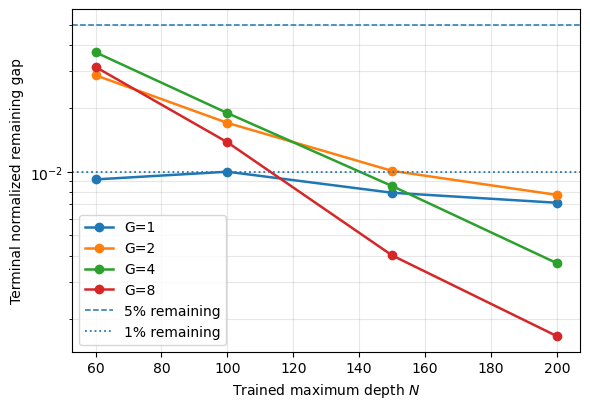

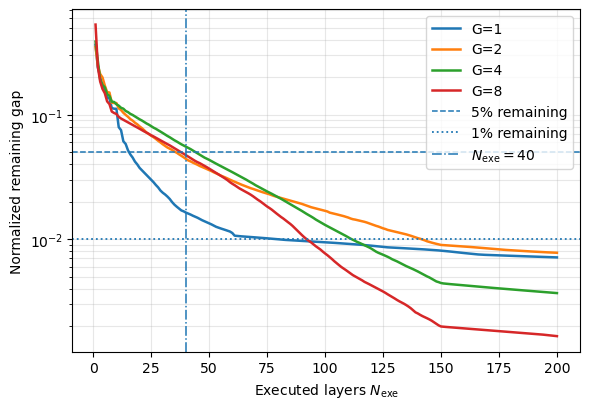

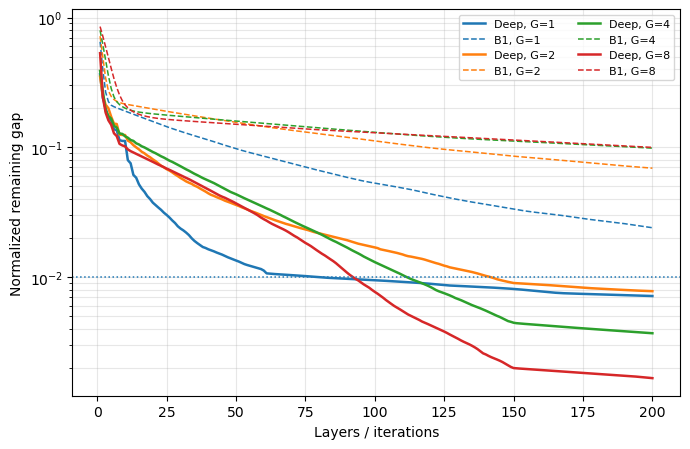


G | selected Nmax | trained N95 | trained N99 | early N95 | early N99 | B1 N95 | B1 N99 | Deep gap@40
----------------------------------------------------------------------------------------------------------------
1 |           200 |          60 |          60 |        16 |        79 |    107 |    nan | 0.016341
2 |           200 |          60 |         200 |        36 |       142 |    nan |    nan | 0.044123
4 |           200 |          60 |         150 |        45 |       112 |    nan |    nan | 0.055436
8 |           200 |          60 |         150 |        38 |        93 |    nan |    nan | 0.047300


In [6]:
# ============================================================
# Figure A: terminal test performance versus TRAINED depth
# This is the cleanest answer to "how deep must the trained model be?"
# ============================================================
plt.figure(figsize=(6.0, 4.2))

for G in G_list:
    r = test_results[G]

    plt.semilogy(
        r["trained_depths"],
        np.maximum(r["candidate_test_gap"], 1e-6),
        marker="o",
        linewidth=1.8,
        label=f"G={G}",
    )

plt.axhline(
    0.05,
    linestyle="--",
    linewidth=1.1,
    label="5% remaining",
)
plt.axhline(
    0.01,
    linestyle=":",
    linewidth=1.3,
    label="1% remaining",
)

plt.xlabel("Trained maximum depth $N$")
plt.ylabel("Terminal normalized remaining gap")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# Figure B: EARLY-EXIT trajectory of each selected long model
# This makes N_exe=40 a natural operating point rather than a
# separately trained arbitrary-depth model.
# ============================================================
plt.figure(figsize=(6.0, 4.2))

for G in G_list:
    curve = test_results[G]["B3_gap_curve"].numpy()
    n = np.arange(1, len(curve) + 1)

    plt.semilogy(
        n,
        np.maximum(curve, 1e-6),
        linewidth=1.8,
        label=f"G={G}",
    )

plt.axhline(
    0.05,
    linestyle="--",
    linewidth=1.1,
    label="5% remaining",
)
plt.axhline(
    0.01,
    linestyle=":",
    linewidth=1.3,
    label="1% remaining",
)
plt.axvline(
    baseline_exec_depth,
    linestyle="-.",
    linewidth=1.1,
    label="$N_{\\rm exe}=40$",
)

plt.xlabel("Executed layers $N_{\\rm exe}$")
plt.ylabel("Normalized remaining gap")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# Figure C: diagnostic B1 versus Deep-SSP trajectories
# ============================================================
plt.figure(figsize=(7.0, 4.6))

for G in G_list:
    deep = test_results[G]["B3_gap_curve"].numpy()
    b1 = test_results[G]["B1_gap_curve"].numpy()
    n = np.arange(1, len(deep) + 1)

    line = plt.semilogy(
        n,
        np.maximum(deep, 1e-6),
        linewidth=1.8,
        label=f"Deep, G={G}",
    )[0]

    plt.semilogy(
        n,
        np.maximum(b1, 1e-6),
        linestyle="--",
        linewidth=1.1,
        color=line.get_color(),
        label=f"B1, G={G}",
    )

plt.axhline(0.01, linestyle=":", linewidth=1.1)
plt.xlabel("Layers / iterations")
plt.ylabel("Normalized remaining gap")
plt.grid(True, which="both", alpha=0.3)
plt.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()


print(
    "\n"
    "G | selected Nmax | trained N95 | trained N99 | "
    "early N95 | early N99 | B1 N95 | B1 N99 | Deep gap@40"
)
print("-" * 112)

for G in G_list:
    r = test_results[G]

    print(
        f"{G:1d} | "
        f"{r['Nmax']:13d} | "
        f"{str(r['trained_N95']):>11s} | "
        f"{str(r['trained_N99']):>11s} | "
        f"{str(r['early_N95']):>9s} | "
        f"{str(r['early_N99']):>9s} | "
        f"{str(r['B1_N95']):>6s} | "
        f"{str(r['B1_N99']):>6s} | "
        f"{r['B3_N40']['gap']:.6f}"
    )


## 7. Save final models and MATLAB-ready data


In [7]:
from scipy.io import savemat

# ============================================================
# Save complete PyTorch package
# ============================================================
final_pt_file = root_dir / (
    "DeepSSP_depth_by_G_terminal_gap_"
    f"g2max{gamma_stage2_max:g}_"
    f"rho{rho:.0e}.pt"
)

torch.save(
    {
        "G_list": G_list,
        "selected_depths": selected_depths,
        "progressive_depths": progressive_depths,
        "target_validation_gap": target_validation_gap,
        "baseline_exec_depth": baseline_exec_depth,
        "reference_iter": reference_iter,
        "rho": rho,
        "dataset_seed": seed,
        "training_seed": training_seed,
        "dataset_signature": dataset_signature,
        "architecture": {
            "stage1_layers": stage1_layers,
            "gamma_stage1_min": gamma_stage1_min,
            "gamma_stage1_max": gamma_stage1_max,
            "gamma_stage2_min": gamma_stage2_min,
            "gamma_stage2_max": gamma_stage2_max,
            "beta_stage2_max": beta_stage2_max,
            "hbf_outer_iter": hbf_outer_iter,
            "hbf_inner_iter": hbf_inner_iter,
        },
        "selected_model_state_dicts": {
            G: cpu_state_dict(selected_models[G])
            for G in G_list
        },
        "progressive_validation": {
            G: {
                int(depth): {
                    "final_valid_gap": float(result["final_valid_gap"]),
                    "best_val_gap": float(result["best_val_gap"]),
                    "best_epoch": int(result["best_epoch"]),
                    "training_time": float(result["training_time"]),
                    "gamma_beta_stats": result["gamma_beta_stats"],
                }
                for depth, result in progressive_results[G].items()
            }
            for G in G_list
        },
        "test_results": test_results,
        "all_supervisors": all_supervisors,
    },
    final_pt_file,
)

print("Saved final PyTorch package:")
print(" ", final_pt_file)


# ============================================================
# MATLAB-ready arrays
# ============================================================
num_G = len(G_list)
global_Nmax = max(selected_depths.values())
max_num_candidates = max(
    len(test_results[G]["trained_depths"])
    for G in G_list
)

candidate_depth_mat = np.full(
    (num_G, max_num_candidates),
    np.nan,
)
candidate_gap_mat = np.full_like(
    candidate_depth_mat,
    np.nan,
)
candidate_sr_mat = np.full_like(
    candidate_depth_mat,
    np.nan,
)
candidate_crlb_mat = np.full_like(
    candidate_depth_mat,
    np.nan,
)

B3_gap_mat = np.full(
    (num_G, global_Nmax),
    np.nan,
)
B1_gap_mat = np.full_like(
    B3_gap_mat,
    np.nan,
)
gamma_mat = np.full_like(
    B3_gap_mat,
    np.nan,
)
beta_mat = np.full_like(
    B3_gap_mat,
    np.nan,
)

trained_N95 = np.full(num_G, np.nan)
trained_N99 = np.full(num_G, np.nan)
early_N95 = np.full(num_G, np.nan)
early_N99 = np.full(num_G, np.nan)
B1_N95 = np.full(num_G, np.nan)
B1_N99 = np.full(num_G, np.nan)

N40_B3_gap = np.full(num_G, np.nan)
N40_B3_obj = np.full(num_G, np.nan)
N40_B3_sr = np.full(num_G, np.nan)
N40_B3_crlb = np.full(num_G, np.nan)

N40_B1_gap = np.full(num_G, np.nan)
N40_B1_obj = np.full(num_G, np.nan)
N40_B1_sr = np.full(num_G, np.nan)
N40_B1_crlb = np.full(num_G, np.nan)

for i, G in enumerate(G_list):
    r = test_results[G]

    nc = len(r["trained_depths"])
    candidate_depth_mat[i, :nc] = r["trained_depths"]
    candidate_gap_mat[i, :nc] = r["candidate_test_gap"]
    candidate_sr_mat[i, :nc] = r["candidate_test_sr"]
    candidate_crlb_mat[i, :nc] = r["candidate_test_crlb"]

    N = r["Nmax"]
    B3_gap_mat[i, :N] = r["B3_gap_curve"].numpy()
    B1_gap_mat[i, :N] = r["B1_gap_curve"].numpy()

    gamma, beta = selected_models[G].get_unfolded_parameters()
    gamma_mat[i, :N] = gamma.detach().cpu().numpy()
    beta_mat[i, :N] = beta.detach().cpu().numpy()

    for arr, key in [
        (trained_N95, "trained_N95"),
        (trained_N99, "trained_N99"),
        (early_N95, "early_N95"),
        (early_N99, "early_N99"),
        (B1_N95, "B1_N95"),
        (B1_N99, "B1_N99"),
    ]:
        value = r[key]
        if np.isfinite(value):
            arr[i] = value

    b3_40 = r["B3_N40"]
    b1_40 = r["B1_N40"]

    N40_B3_gap[i] = b3_40["gap"]
    N40_B3_obj[i] = b3_40["objective"]
    N40_B3_sr[i] = b3_40["sr"]
    N40_B3_crlb[i] = b3_40["crlb"]

    N40_B1_gap[i] = b1_40["gap"]
    N40_B1_obj[i] = b1_40["objective"]
    N40_B1_sr[i] = b1_40["sr"]
    N40_B1_crlb[i] = b1_40["crlb"]


mat_file = root_dir / (
    "DeepSSP_depth_by_G_terminal_gap_"
    f"g2max{gamma_stage2_max:g}_Fig_data.mat"
)

savemat(
    mat_file,
    {
        "G_list": np.asarray(G_list, dtype=np.int32),
        "selected_Nmax": np.asarray(
            [selected_depths[G] for G in G_list],
            dtype=np.int32,
        ),
        "candidate_trained_depth": candidate_depth_mat,
        "candidate_test_gap": candidate_gap_mat,
        "candidate_test_SR": candidate_sr_mat,
        "candidate_test_CRLB": candidate_crlb_mat,
        "N_axis": np.arange(
            1,
            global_Nmax + 1,
            dtype=np.int32,
        ),
        "B3_gap": B3_gap_mat,
        "B1_gap": B1_gap_mat,
        "gamma_B3": gamma_mat,
        "beta_B3": beta_mat,
        "trained_N95": trained_N95,
        "trained_N99": trained_N99,
        "early_N95": early_N95,
        "early_N99": early_N99,
        "B1_N95": B1_N95,
        "B1_N99": B1_N99,
        "baseline_exec_depth": np.int32(baseline_exec_depth),
        "N40_B3_gap": N40_B3_gap,
        "N40_B3_objective": N40_B3_obj,
        "N40_B3_SR": N40_B3_sr,
        "N40_B3_CRLB": N40_B3_crlb,
        "N40_B1_gap": N40_B1_gap,
        "N40_B1_objective": N40_B1_obj,
        "N40_B1_SR": N40_B1_sr,
        "N40_B1_CRLB": N40_B1_crlb,
        "rho": float(rho),
        "gamma_stage1_max": float(gamma_stage1_max),
        "gamma_stage2_max": float(gamma_stage2_max),
        "beta_stage2_max": float(beta_stage2_max),
        "stage1_layers": np.int32(stage1_layers),
        "reference_iter": np.int32(reference_iter),
        "Nt": np.int32(Nt),
        "Nr": np.int32(Nr),
        "K": np.int32(K),
        "M": np.int32(M),
        "N_RF": np.int32(nrf),
        "dataset_seed": np.int64(seed),
        "training_seed": np.int64(training_seed),
    },
)

print("\nSaved MATLAB-ready depth data:")
print(" ", mat_file)


Saved final PyTorch package:
  trained_weight_models/gc_deep_ssp_depth_by_G_terminal_gap_g2max3/DeepSSP_depth_by_G_terminal_gap_g2max3_rho1e-03.pt

Saved MATLAB-ready depth data:
  trained_weight_models/gc_deep_ssp_depth_by_G_terminal_gap_g2max3/DeepSSP_depth_by_G_terminal_gap_g2max3_Fig_data.mat
